## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


def get_device():
    """
      Return the computing device used in the current session.
    """
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = get_device()
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))


CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Using device: cuda
Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [3]:
import os
import random
import json
import time
import math
import zipfile
import shutil
from dataclasses import dataclass
from typing import Optional, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_SC_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TRAIN_HC_FILE = "Phase_1_Pretraining/Train/train_high_courts.json"
TRAIN_TRI_FILE = "Phase_1_Pretraining/Train/train_tribunals.json"
TRAIN_ACTS_FILE = "Phase_1_Pretraining/Train/train_acts.json"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
PROPORTION = {
    "acts": 0.25,
    "sc": 0.25,
    "hc": 0.30,
    "tri": 0.20
}
EPOCHS = 1
SEED = 42
random.seed(SEED)
VOCAB_SIZE = 30000;
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 768
N_LAYER = 16
N_HEAD = 8

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-gpt2-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

Configuration loaded.


## 4. Load Tokenizer

In [4]:
# %%writefile a1_tokenizer.py
"""Expose your Assignment-1 BPE implementation to Assignment 3.

Reuse your A-1 tokenizer code/class here. The important change is that it must be
RETRAINED on the `train_text` supplied by Assignment 3 rather than reusing a tokenizer
trained on the Assignment-1 dataset.
"""

''' Required returned interface:
      tokenizer.encode(text) -> sequence of integer ids
      tokenizer.decode(ids) -> string
      tokenizer.vocab_size OR tokenizer.get_vocab_size()'''
import re
from tqdm import tqdm
from collections import defaultdict, Counter

class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.merges = []
        self.itos = list(self.reserved)
        self.stoi = {}
        self.ranks = {}
        self.merged_map = {}
        self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(pattern, re.UNICODE)
        
    def _split_text(self, text):
        """Splits text into chunks preserving whitespace, or falls back to basic regex split."""
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        return re.findall(pattern, str(text), flags=re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in self._split_text(text):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes
        self.merges = []

        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break

                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break

                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)

                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair

                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []
                    i = 0
                    n = len(word)

                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1

                    new_word = tuple(new_word)

                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        for chunk in self._split_text(text):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids

    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            if 0 <= idx < len(self.itos):
                tok = self.itos[idx]
            else:
                tok = "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer

## 5. Download Training Data From Hugging Face

In [5]:
from huggingface_hub import hf_hub_download

train_sc_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_SC_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)
train_hc_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_HC_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)
train_tri_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_TRI_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)
train_acts_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_ACTS_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Training file:")
print(train_sc_file_path)



Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_tribunal(…): reconstructing file:   0%|          |  0.00B / 6.48GB            

Phase_1_Pretraining/Train/train_tribunal(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


In [6]:
import re, unicodedata
from collections import Counter

def clean_court_text(text, ascii_only=True, tables="flatten"):
    """Clean one judgment text. tables: 'flatten' | 'drop' | 'keep'.
    Dates, case numbers, court/judge names are never reformatted (integrity-checked)."""
    ROW = "\x01"
    SEP = re.compile(r"\s{3,}|\|")
    BORDER = re.compile(r"^[\s|+\-_=:.]{3,}$")
    PARA = re.compile(r"^(?:\(?\d{1,3}(?:\.\d+)*[.)]|\d{1,3}\.\d+|\(?[ivxlc]{1,5}\)|\(?[a-zA-Z]\)|-)\s+\S")
    MON = r"(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)[a-z]*"
    ENT = [re.compile(p, re.I) for p in (
        r"\b\d{1,2}\s*[./-]\s*\d{1,2}\s*[./-]\s*\d{2,4}\b",
        rf"\b\d{{1,2}}(?:st|nd|rd|th)?\s+{MON}\.?,?\s+\d{{4}}\b",
        rf"\b{MON}\.?\s+\d{{1,2}}(?:st|nd|rd|th)?,?\s+\d{{4}}\b",
        r"\b\d{1,7}\s*(?:of|/)\s*(?:19|20)\d{2}\b", r"\b(?:Supreme|High)\s+Court\b")]
    NOISE = [re.compile(p, re.I | re.M) for p in (
        r"indian\s*kanoon\s*-?\s*https?://\S+", r"https?://\S+", r"</?[a-z][^>]{0,100}>",
        r"\bdigitally\s+signed\s+by\b[^\n]*", r"\bsignature\s+not\s+verified\b[^\n]*",
        r"^\s*page\s+\d+\s*(?:of|/)\s*\d+\s*$")]
    DOTS = [(r"(?:\.[ \t]){3,}\.?", " ... "), (r"\.{4,}", " ... "), (r"(?<=\w)\.\.(?=\s|$)", "."),
            (r"([,;:!?])\1+", r"\1"), (r"[_=~*#]{3,}|-{3,}", " "), (r"[ \t]+([,;])(?=\s)", r"\1")]
    typo = {"\u2018": "'", "\u2019": "'", "\u201a": "'", "\u201b": "'", "\u2032": "'", "\u00b4": "'", "`": "'",
            "\u201c": '"', "\u201d": '"', "\u201e": '"', "\u201f": '"', "\u2033": '"', "\u00ab": '"', "\u00bb": '"',
            "\u2013": "-", "\u2014": "-", "\u2015": "-", "\u2010": "-", "\u2011": "-", "\u2012": "-", "\u2212": "-",
            "\u2026": "...", "\u2022": "- ", "\u25cf": "- ", "\u25aa": "- ", "\u25a0": "- ", "\u00b7": "- ",
            "\u20b9": "Rs.", "\u00a9": "(c)", "\u00ae": "", "\u2122": "", "\u00d7": "x", "\u00f7": "/",
            "\u2044": "/", "\u00a0": " ", "\u202f": " ", "\u205f": " ", "\u3000": " ", "\u2028": "\n", "\u2029": "\n\n"}
    typo.update({chr(c): " " for c in range(0x2000, 0x200b)})
    typo.update({chr(c): ("|" if chr(c) in "\u2502\u2503\u2551\u254e\u254f\u2506\u2507\u250a\u250b" else "-")
                 for c in range(0x2500, 0x2580)})
    typo = str.maketrans(typo)
    moji = re.compile(r"(?:[\u00c2-\u00f4][\u0080-\u00bf\u20ac\u201a\u0192\u201e\u2026\u2020\u2021\u02c6\u2030\u0160"
                      r"\u2039\u0152\u017d\u2018\u2019\u201c\u201d\u2022\u2013\u2014\u02dc\u2122\u0161\u203a\u0153"
                      r"\u017e\u0178]+)+")
    ctrl = re.compile(r"[\u200b-\u200f\u202a-\u202e\u2060\ufeff\u00ad\ufffd\ue000-\uf8ff\x00-\x08\x0b\x0e-\x1f\x7f]|\(cid:\d+\)")

    def fix_moji(s):
        def f(m):
            try:
                b = bytearray()
                for ch in m.group(0):
                    try: b += ch.encode("cp1252")
                    except UnicodeEncodeError:
                        if "\u0080" <= ch <= "\u009f": b.append(ord(ch))
                        else: raise
                return bytes(b).decode("utf-8")
            except (UnicodeEncodeError, UnicodeDecodeError):
                return m.group(0)
        return moji.sub(f, s)

    def ws(s):
        return re.sub(r"\n{3,}", "\n\n", re.sub(r" ?\n ?", "\n", re.sub(r"[ \t]+", " ", s))).strip()

    def entities(s):
        return {re.sub(r"\s+", "", m.group(0)).lower() for rx in ENT for m in rx.finditer(s)}

    def denoise(s):
        for rx in NOISE: s = rx.sub(" ", s)
        return s

    def heading(t):
        t = t.strip()
        return (t.startswith(ROW) or bool(re.fullmatch(r"(?i)(versus|vs?\.?|v/s)", t))
                or (len(t.split()) <= 14 and "..." in t and re.search(r"(?i)(petitioner|respondent|appellant|applicant|defendant|plaintiff)s?\W*$", t) is not None)
                or (len(t) >= 3 and t.isupper() and len(t.split()) <= 10))

    def run(src, conservative):
        s = fix_moji(src).replace("\x0c", "\n").replace("\t", "   ").replace("\r\n", "\n").replace("\r", "\n")
        s = ctrl.sub("", s).translate(typo)
        s = (unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode() if ascii_only
             else unicodedata.normalize("NFKC", s))
        base = entities(denoise(s))
        if not conservative:
            L = denoise(s).split("\n")
            # one-cell-per-line tables
            tiny = lambda l: (0 < len(l.strip()) <= 25 and re.search(r"[A-Za-z0-9]", l) and not re.search(r"[.:;?!]$", l.strip())
                              and not PARA.match(l.strip()) and not SEP.search(l.strip()))
            o, i = [], 0
            while i < len(L):
                j = i
                while tiny(L[i]) and j < len(L) and tiny(L[j]): j += 1
                if j - i >= 8:
                    if tables == "flatten": o.append(ROW + "; ".join(x.strip() for x in L[i:j]))
                    i = j
                else:
                    o.append(L[i]); i += 1
            L = o
            # row/column tables
            if tables != "keep":
                isrow = lambda l: bool(l.strip()) and bool(SEP.search(l.strip()))
                isb = lambda l: bool(BORDER.match(l.strip() or "x"))
                o, i = [], 0
                while i < len(L):
                    if isrow(L[i]) or isb(L[i]):
                        j = i
                        while j < len(L) and (isrow(L[j]) or isb(L[j])): j += 1
                        rows = [l for l in L[i:j] if not isb(l)]
                        if len(rows) >= 3 or any(len(SEP.findall(r.strip())) >= 2 for r in rows) or len(rows) < j - i:
                            if tables == "flatten":
                                o += [ROW + "; ".join(c.strip() for c in SEP.split(r.strip()) if c.strip()) for r in rows]
                            i = j; continue
                    o.append(L[i]); i += 1
                L = o
            # page numbers / symbol-only lines
            L = [l for l in L if not (l.strip() and (re.fullmatch(r"[-\[(]?\s*\d{1,4}\s*[-\])]?", l.strip())
                                                       or not re.search(r"[A-Za-z0-9]", l.strip().replace(ROW, ""))))]
            # repeated headers/footers (keep first copy)
            key = lambda l: (lambda t: re.sub(r"\d+", "#", t) if re.search(r"\bpage\b", t) else t)(re.sub(r"\s+", " ", l.strip().lower()))
            cnt = Counter(key(l) for l in L if 20 <= len(l.strip()) <= 120 and not PARA.match(l.strip()))
            seen, o = set(), []
            for l in L:
                k = key(l)
                if cnt.get(k, 0) >= 3:
                    if k in seen: continue
                    seen.add(k)
                o.append(l)
            s = re.sub(r"(?<=[a-z])-\n\s*(?=[a-z])", "", "\n".join(o))
            # unwrap hard line breaks
            res, cur = [], ""
            for l in s.split("\n"):
                t = l.strip()
                if not t:
                    if cur: res.append(cur); cur = ""
                    res.append(""); continue
                if cur and not PARA.match(t) and not heading(t) and not heading(cur): cur += " " + t
                else:
                    if cur: res.append(cur)
                    cur = t
            if cur: res.append(cur)
            s = "\n".join(res)
        for p, r in DOTS: s = re.sub(p, r, s)
        s = ws(s.replace(ROW, ""))
        if entities(s) != base:                      # safety net: never alter dates / case numbers / courts
            return run(src, True) if not conservative else ws(fix_moji(src))
        return s

    return run(text, False) if isinstance(text, str) else text

In [7]:
%pip install ijson

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.2/150.2 kB 7.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [8]:
from tqdm import tqdm
import ijson

MIN_CHARS = 200            # lower this if your acts/tribunal docs are short
MAX_DOCS_PER_SOURCE = 100_000

if not (os.path.exists("./cs781_phase1/tokenizer.pkl")
        and os.path.exists("./cs781_phase1/train_tokens.pt")
        and os.path.exists("./cs781_phase1/val_tokens.pt")):
    random.seed(SEED)
    train_text = []

    for path in [train_acts_file_path, train_sc_file_path, train_hc_file_path, train_tri_file_path]:
        kept = dropped = 0
        with open(path, "r", encoding="utf-8") as f:
            for data in tqdm(ijson.items(f, "item")):
                text = data.get("text")
                if not isinstance(text, str):
                    dropped += 1
                    continue
                cleaned = clean_court_text(text)
                if len(cleaned) < MIN_CHARS:        # replaces the old `is None` check
                    dropped += 1
                    continue
                train_text.append(cleaned)
                kept += 1
                if kept >= MAX_DOCS_PER_SOURCE:
                    break
        print(f"dropped {dropped:,}")

In [9]:
# # 
# %rm "/kaggle/working/cs781_phase1/val_tokens.pt"

In [10]:
import pickle
if not os.path.exists(OUTPUT_DIR+"/tokenizer.pkl"):
    tokenizer = train_tokenizer(train_text, VOCAB_SIZE)
    with open(OUTPUT_DIR+"/tokenizer.pkl", "wb") as f:
        pickle.dump(tokenizer, f)
else:
    with open(OUTPUT_DIR+"/tokenizer.pkl", "rb") as f:
        tokenizer = pickle.load(f)

## 6. Create Train and Validation Tokens Set

In [11]:
if not (os.path.exists(OUTPUT_DIR+"/tokenizer.pkl") and os.path.exists(OUTPUT_DIR+"/train_tokens.pt") and os.path.exists(OUTPUT_DIR+"/val_tokens.pt")):
    train_tokens = []
    val_tokens = []

    random.seed(SEED)
    sources = list(PROPORTION.keys())
    proportions = list(PROPORTION.values())
    
    target_train_per_source = [int(TRAIN_TOKENS * p) for p in proportions]
    target_val_per_source = [int(VAL_TOKENS * p) for p in proportions]
    
    for idx, (path, name) in enumerate(zip([train_acts_file_path, train_sc_file_path, train_hc_file_path, train_tri_file_path], sources)):
        source_train_collected = 0
        source_val_collected = 0
        
        target_train = target_train_per_source[idx]
        target_val = target_val_per_source[idx]
    
        print(f"Processing source: {name} (Target Train: {target_train:,}, Target"
              f" Val: {target_val:,})"
        )
        with open(path,"r", encoding="utf-8") as f:
            records = ijson.items(f, 'item')
            for data in tqdm(records):
                text = data["text"]
                text = clean_court_text(text)
                if not isinstance(text, str):
                    continue
                tokens = tokenizer.encode(text)
            
                if random.random() < 0.05:
                    if source_val_collected < target_val:
                       needed = target_val - source_val_collected
                       chunk = tokens[:needed]
                       val_tokens.extend(chunk)
                       source_val_collected += len(chunk)
                else:
                    if source_train_collected < target_train:
                       needed = target_train - source_train_collected
                       chunk = tokens[:needed]
                       train_tokens.extend(chunk)
                       source_train_collected += len(chunk)
                if (
                    source_train_collected >= target_train
                    and source_val_collected >= target_val
                ):
                  break

    # Save tokens as PyTorch tensors (.pt)
    print("Saving generated tokens...")
    torch.save(train_tokens, os.path.join(OUTPUT_DIR, "train_tokens.pt"))
    torch.save(val_tokens, os.path.join(OUTPUT_DIR, "val_tokens.pt"))
    print(
      f"Finished! Total Train Tokens: {len(train_tokens):,}, Total Val"
      f" Tokens: {len(val_tokens):,}"
    )
else:
    train_tokens = torch.load(os.path.join(OUTPUT_DIR, "train_tokens.pt"), map_location="cpu")
    val_tokens = torch.load(os.path.join(OUTPUT_DIR, "val_tokens.pt"), map_location="cpu")
    print("Tokenizer and token files already exist. Skipping tokenization.")

Tokenizer and token files already exist. Skipping tokenization.


## 7. Create Token Blocks

In [12]:
def get_batch(data, batch_size, block_size):
    """Random windows from the WHOLE token stream -> every batch mixes acts / HC / SC / tribunals."""
    ix = torch.randint(0, len(data) - block_size - 1, (batch_size,)).tolist()
    x = torch.stack([data[i:i + block_size] for i in ix]).long()
    y = torch.stack([data[i + 1:i + 1 + block_size] for i in ix]).long()
    return x, y

print("Train sequences available:", (len(train_tokens) - 1) // TRAIN_BLOCK_SIZE)
print("Val sequences available:  ", (len(val_tokens) - 1) // TRAIN_BLOCK_SIZE)

Train sequences available: 97656
Val sequences available:   2441


## 8. Create Datasets

In [13]:
# from datasets import Dataset

# train_dataset = Dataset.from_dict({"input_ids": train_blocks})
# val_dataset = Dataset.from_dict({"input_ids": val_blocks})

# print(train_dataset)
# print(val_dataset)

## 9. Define The Model

## LMConfig

In [14]:
@dataclass
class LMConfig:
    # ---- general ----
    vocab_size: int = VOCAB_SIZE
    max_seq_len: int = MODEL_CONTEXT_LENGTH
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    dropout: float = 0.0
    bias: bool = False
    tie_embeddings: bool = True
    norm_type: str = "rmsnorm"          # "rmsnorm" | "layernorm"
    norm_eps: float = 1e-6

    # ---- positional ----
    pos_emb_type: str = "rope"          # "rope" | "sinusoidal"
    rope_theta: float = 10000.0

    # ---- attention ----
    attn_type: str = "gqa"              # "gqa" | "mla"
    n_heads: int = N_HEAD
    # GQA (n_kv_heads == n_heads -> MHA, 1 -> MQA)
    n_kv_heads: int = 2
    head_dim: Optional[int] = None      # defaults to d_model // n_heads
    # MLA
    q_lora_rank: Optional[int] = 256    # None -> no query compression
    kv_lora_rank: int = 128
    qk_nope_head_dim: int = 48
    qk_rope_head_dim: int = 16
    v_head_dim: int = 64

    # ---- feed-forward ----
    ffn_type: str = "dense"             # "dense" | "moe"
    d_ff: int = 2048
    # MoE
    n_experts: int = 8
    top_k: int = 2
    n_shared_experts: int = 1
    expert_d_ff: int = 512
    aux_loss_coef: float = 0.01
    first_k_dense_layers: int = 0       # first k layers stay dense
    moe_layer_freq: int = 1             # after that, every n-th layer is MoE

    def __post_init__(self):
        assert self.norm_type in ("rmsnorm", "layernorm")
        assert self.pos_emb_type in ("rope", "sinusoidal")
        assert self.attn_type in ("gqa", "mla")
        assert self.ffn_type in ("dense", "moe")

        if self.pos_emb_type == "sinusoidal":
            assert self.d_model % 2 == 0, "sinusoidal needs even d_model"

        if self.attn_type == "gqa":
            if self.head_dim is None:
                assert self.d_model % self.n_heads == 0, "d_model must be divisible by n_heads"
                self.head_dim = self.d_model // self.n_heads
            assert self.n_heads % self.n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
            if self.pos_emb_type == "rope":
                assert self.head_dim % 2 == 0, "RoPE needs even head_dim"
        else:
            if self.pos_emb_type == "rope":
                assert self.qk_rope_head_dim % 2 == 0 and self.qk_rope_head_dim > 0

        if self.ffn_type == "moe":
            assert 1 <= self.top_k <= self.n_experts

    @property
    def rope_dim(self) -> int:
        return self.qk_rope_head_dim if self.attn_type == "mla" else self.head_dim

    def is_moe_layer(self, layer_idx: int) -> bool:
        if self.ffn_type != "moe" or layer_idx < self.first_k_dense_layers:
            return False
        return (layer_idx - self.first_k_dense_layers) % self.moe_layer_freq == 0

## Normalization layers

In [15]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.weight.float()).to(dtype)


def make_norm(cfg: LMConfig, dim: int) -> nn.Module:
    if cfg.norm_type == "rmsnorm":
        return RMSNorm(dim, cfg.norm_eps)
    return nn.LayerNorm(dim, eps=cfg.norm_eps)

## Positional embeddings (RoPE and sinusoidal)

In [16]:
class RoPE(nn.Module):
    """Rotary embedding. Rotates q and k of shape (B, H, T, dim)."""

    def __init__(self, dim: int, max_seq_len: int, theta: float = 10000.0):
        super().__init__()
        inv_freq = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
        t = torch.arange(max_seq_len).float()
        freqs = torch.outer(t, inv_freq)               # (L, dim/2)
        emb = torch.cat([freqs, freqs], dim=-1)        # (L, dim)
        self.register_buffer("cos", emb.cos(), persistent=False)
        self.register_buffer("sin", emb.sin(), persistent=False)

    @staticmethod
    def _rotate_half(x):
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat([-x2, x1], dim=-1)

    def rotate(self, x, positions):
        cos, sin = self.cos[positions], self.sin[positions]
        if cos.dim() == 2:                              # positions: (T,)
            cos, sin = cos[None, None], sin[None, None]
        else:                                           # positions: (B, T)
            cos, sin = cos[:, None], sin[:, None]
        cos, sin = cos.to(x.dtype), sin.to(x.dtype)
        return x * cos + self._rotate_half(x) * sin

    def forward(self, q, k, positions):
        return self.rotate(q, positions), self.rotate(k, positions)


class SinusoidalPositionalEmbedding(nn.Module):
    """Fixed sin/cos table, added to token embeddings once at model level."""

    def __init__(self, d_model: int, max_seq_len: int):
        super().__init__()
        pos = torch.arange(max_seq_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_seq_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, x, offset: int = 0):
        T = x.size(1)
        return x + self.pe[offset:offset + T].to(x.dtype)

## Attention helper and GQA

In [17]:
def causal_sdpa(q, k, v, dropout_p: float = 0.0, training: bool = False):
    """Causal attention that also works when k/v are longer than q (KV cache)."""
    Tq, Tk = q.size(2), k.size(2)
    p = dropout_p if training else 0.0
    if Tq == Tk:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p, is_causal=True)
    if Tq == 1:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p)
    mask = torch.ones(Tq, Tk, dtype=torch.bool, device=q.device).tril(diagonal=Tk - Tq)
    return F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=p)


def masked_sdpa(q, k, v, attn_mask, dropout_p=0.0, training=False):
    if attn_mask is None:
        return causal_sdpa(q, k, v, dropout_p, training)            # training path unchanged
    return F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                          dropout_p=dropout_p if training else 0.0)

class GQAttention(nn.Module):
    """Grouped-query attention. cache = (k, v), each (B, n_kv_heads, T, head_dim)."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.n_heads, self.n_kv, self.hd = cfg.n_heads, cfg.n_kv_heads, cfg.head_dim
        self.q_proj = nn.Linear(cfg.d_model, self.n_heads * self.hd, bias=cfg.bias)
        self.k_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.v_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.o_proj = nn.Linear(self.n_heads * self.hd, cfg.d_model, bias=cfg.bias)
        self.dropout = cfg.dropout

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.hd).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        if rope is not None:
            q, k = rope(q, k, positions)
        if kv_cache is not None:
            k = torch.cat([kv_cache[0], k], dim=2)
            v = torch.cat([kv_cache[1], v], dim=2)
        new_cache = (k, v)
        rep = self.n_heads // self.n_kv
        out = masked_sdpa(q, k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1),
                          attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.n_heads * self.hd)
        return self.o_proj(out), new_cache

## MLA

In [18]:
class MLAttention(nn.Module):
    """
    Multi-head Latent Attention (DeepSeek-style, un-absorbed version).
    cache = (latent (B, 1, T, kv_lora_rank), k_rope (B, 1, T, rope_dim) or None).
    Only the compressed latent and the small shared k_rope are cached.
    With sinusoidal positions the decoupled RoPE part is dropped (rope_dim = 0).
    """

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.H = cfg.n_heads
        self.dn = cfg.qk_nope_head_dim
        self.dr = cfg.qk_rope_head_dim if cfg.pos_emb_type == "rope" else 0
        self.dv = cfg.v_head_dim
        self.dropout = cfg.dropout

        q_out = self.H * (self.dn + self.dr)
        if cfg.q_lora_rank:
            self.q_down = nn.Linear(cfg.d_model, cfg.q_lora_rank, bias=cfg.bias)
            self.q_norm = make_norm(cfg, cfg.q_lora_rank)
            self.q_up = nn.Linear(cfg.q_lora_rank, q_out, bias=False)
            self.q_proj = None
        else:
            self.q_proj = nn.Linear(cfg.d_model, q_out, bias=cfg.bias)

        self.kv_down = nn.Linear(cfg.d_model, cfg.kv_lora_rank, bias=cfg.bias)
        self.kv_norm = make_norm(cfg, cfg.kv_lora_rank)
        self.kv_up = nn.Linear(cfg.kv_lora_rank, self.H * (self.dn + self.dv), bias=False)
        self.k_rope_proj = nn.Linear(cfg.d_model, self.dr, bias=cfg.bias) if self.dr > 0 else None
        self.o_proj = nn.Linear(self.H * self.dv, cfg.d_model, bias=cfg.bias)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_up(self.q_norm(self.q_down(x))) if self.q_proj is None else self.q_proj(x)
        q = q.view(B, T, self.H, self.dn + self.dr).transpose(1, 2)
        latent = self.kv_norm(self.kv_down(x)).unsqueeze(1)
        k_rope = None
        if self.dr > 0:
            q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
            k_rope = self.k_rope_proj(x).unsqueeze(1)
            q_rope, k_rope = rope(q_rope, k_rope, positions)
        else:
            q_nope = q
        if kv_cache is not None:
            latent = torch.cat([kv_cache[0], latent], dim=2)
            if k_rope is not None:
                k_rope = torch.cat([kv_cache[1], k_rope], dim=2)
        new_cache = (latent, k_rope)
        Tk = latent.size(2)
        kv = self.kv_up(latent.squeeze(1)).view(B, Tk, self.H, self.dn + self.dv).transpose(1, 2)
        k_nope, v = kv.split([self.dn, self.dv], dim=-1)
        if self.dr > 0:
            q_full = torch.cat([q_nope, q_rope], dim=-1)
            k_full = torch.cat([k_nope, k_rope.expand(-1, self.H, -1, -1)], dim=-1)
        else:
            q_full, k_full = q_nope, k_nope
        out = masked_sdpa(q_full, k_full, v, attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.H * self.dv)
        return self.o_proj(out), new_cache


ATTN_REGISTRY = {"gqa": GQAttention, "mla": MLAttention}

## Feed-forward networks (GeLU)

In [19]:
class DenseFFN(nn.Module):
    """Linear -> GeLU -> Linear. Returns (out, aux_loss=0)."""

    def __init__(self, cfg: LMConfig, d_ff: Optional[int] = None):
        super().__init__()
        d_ff = d_ff or cfg.d_ff
        self.fc1 = nn.Linear(cfg.d_model, d_ff, bias=cfg.bias)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(d_ff, cfg.d_model, bias=cfg.bias)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x))), x.new_zeros(())


class MoEFFN(nn.Module):
    """Top-k routed experts (DenseFFN each) + optional always-on shared experts."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.E, self.k = cfg.n_experts, cfg.top_k
        self.router = nn.Linear(cfg.d_model, self.E, bias=False)
        self.experts = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(self.E)])
        self.shared = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(cfg.n_shared_experts)])

    def forward(self, x):
        B, T, D = x.shape
        flat = x.reshape(-1, D)                                  # (N, D)

        probs = self.router(flat).float().softmax(dim=-1)        # (N, E)
        topv, topi = probs.topk(self.k, dim=-1)                  # (N, k)
        topv = topv / topv.sum(dim=-1, keepdim=True)             # renormalise

        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            tok_idx, slot = (topi == e).nonzero(as_tuple=True)
            if tok_idx.numel() == 0:
                continue
            y, _ = expert(flat[tok_idx])
            w = topv[tok_idx, slot].unsqueeze(-1).to(y.dtype)
            out.index_add_(0, tok_idx, (y * w).to(out.dtype))

        for sh in self.shared:
            out = out + sh(flat)[0]

        # Switch-style load-balancing loss: E * sum_i f_i * P_i
        if self.training:
            f = F.one_hot(topi, self.E).sum(dim=1).float().mean(dim=0) / self.k
            P = probs.mean(dim=0)
            aux = self.E * (f * P).sum()
        else:
            aux = x.new_zeros(())
        return out.view(B, T, D), aux


FFN_REGISTRY = {"dense": DenseFFN, "moe": MoEFFN}

## TransformerBlock

In [20]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg: LMConfig, layer_idx: int):
        super().__init__()
        self.norm1 = make_norm(cfg, cfg.d_model)
        self.attn = ATTN_REGISTRY[cfg.attn_type](cfg)
        self.norm2 = make_norm(cfg, cfg.d_model)
        self.ffn = FFN_REGISTRY["moe" if cfg.is_moe_layer(layer_idx) else "dense"](cfg)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        a, new_cache = self.attn(self.norm1(x), rope, positions, kv_cache, attn_mask)
        x = x + self.drop(a)
        f, aux = self.ffn(self.norm2(x))
        x = x + self.drop(f)
        return x, aux, new_cache

## DecoderLM

In [21]:
class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.sin_emb = (SinusoidalPositionalEmbedding(cfg.d_model, cfg.max_seq_len)
                        if cfg.pos_emb_type == "sinusoidal" else None)
        self.rope = (RoPE(cfg.rope_dim, cfg.max_seq_len, cfg.rope_theta)
                     if cfg.pos_emb_type == "rope" else None)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg, i) for i in range(cfg.n_layers)])
        self.final_norm = make_norm(cfg, cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        # scaled init on residual output projections
        for name, p in self.named_parameters():
            if name.endswith("o_proj.weight") or name.endswith("fc2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None, kv_caches=None, use_cache=False,
                last_only=False, attention_mask=None):
        B, T = input_ids.shape
        past = 0 if kv_caches is None else kv_caches[0][0].size(2)
        dev = input_ids.device
        if attention_mask is None:                                      # training / unpadded: unchanged behaviour
            assert past + T <= self.cfg.max_seq_len, "sequence exceeds max_seq_len"
            positions = torch.arange(past, past + T, device=dev)        # (T,)
            attn_mask = None
        else:
            am = attention_mask.to(dev).bool()
            assert am.shape == (B, past + T), f"attention_mask must be (B, past+T) = {(B, past + T)}"
            positions = (am.long().cumsum(-1) - 1).clamp(min=0)[:, past:]            # (B, T) per-row positions
            q_idx = torch.arange(past, past + T, device=dev)[:, None]
            k_idx = torch.arange(past + T, device=dev)[None, :]
            # causal AND key is a real token; the diagonal is always allowed so padded query rows never become all -inf
            attn_mask = ((k_idx <= q_idx)[None, None] & am[:, None, None, :]) | (k_idx == q_idx)[None, None]
    
        x = self.tok_emb(input_ids)
        if self.sin_emb is not None:
            x = x * math.sqrt(self.cfg.d_model) + self.sin_emb.pe[positions].to(x.dtype)
        x = self.drop(x)
    
        aux_total = x.new_zeros(())
        new_caches = []
        for i, block in enumerate(self.blocks):
            cache_i = None if kv_caches is None else kv_caches[i]
            x, aux, new_cache = block(x, self.rope, positions, cache_i, attn_mask)
            aux_total = aux_total + aux
            new_caches.append(new_cache)
    
        x = self.final_norm(x)
        if last_only:
            x = x[:, -1:, :]
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            ce = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1), ignore_index=-100)
            loss = ce + self.cfg.aux_loss_coef * aux_total
        caches = new_caches if (use_cache or kv_caches is not None) else None
        return logits, loss, caches

    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=400, temperature=0.4, top_k=50, top_p=0.9,
                 repetition_penalty=1.1, rep_window=256, no_repeat_ngram=0, ban_ids=(), pad_id=0, 
                 tokenizer=None, target_words=None, check_every=16):
        """input_ids: (B, L) LEFT-padded; attention_mask: (B, L) with 1 for real tokens, 0 for padding."""
        was_training = self.training
        self.eval()
        B, L = input_ids.shape
        dev = input_ids.device
        attn = (torch.ones(B, L, dtype=torch.long, device=dev) if attention_mask is None
                else attention_mask.to(dev).long())
        assert int(attn.sum(1).max()) + max_new_tokens <= self.cfg.max_seq_len, \
            "longest prompt + new tokens exceed max_seq_len"
        ban = torch.tensor(sorted(set(ban_ids)), dtype=torch.long, device=dev) if len(ban_ids) else None
    
        n = no_repeat_ngram
        seen = [dict() for _ in range(B)]
        hist = [[] for _ in range(B)]
    
        gen = input_ids.new_zeros((B, 0))
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        caches, cur = None, input_ids
        for step in range(max_new_tokens):
            logits, _, caches = self(cur, kv_caches=caches, use_cache=True, last_only=True, attention_mask=attn)
            logits = logits[:, -1, :].float()
            if ban is not None:
                logits[:, ban] = float("-inf")
            if repetition_penalty != 1.0 and gen.size(1) > 0:
                recent = gen[:, -rep_window:]
                sc = torch.gather(logits, 1, recent)
                sc = torch.where(sc > 0, sc / repetition_penalty, sc * repetition_penalty)
                logits.scatter_(1, recent, sc)
            if n > 1:
                for b in range(B):
                    if len(hist[b]) >= n - 1:
                        banned = seen[b].get(tuple(hist[b][-(n - 1):]))
                        if banned:
                            logits[b, list(banned)] = float("-inf")
    
            if temperature <= 0:
                nxt = logits.argmax(dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k:
                    kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, -1, None]
                    logits = logits.masked_fill(logits < kth, float("-inf"))
                if top_p and top_p < 1.0:
                    sl, si = torch.sort(logits, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    sl = sl.masked_fill(pr.cumsum(-1) - pr > top_p, float("-inf"))
                    logits = torch.full_like(logits, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
    
            nxt = torch.where(done.unsqueeze(1), torch.full_like(nxt, pad_id), nxt)
            if n > 1:
                for b, t in enumerate(nxt.squeeze(1).tolist()):
                    h = hist[b]
                    if len(h) >= n - 1:
                        seen[b].setdefault(tuple(h[-(n - 1):]), set()).add(t)
                    h.append(t)
            gen = torch.cat([gen, nxt], dim=1)
            cur = nxt
            attn = torch.cat([attn, torch.ones(B, 1, dtype=attn.dtype, device=dev)], dim=1)   # new token is a real token
    
            if target_words is not None and (step + 1) % check_every == 0:
                for b in torch.nonzero(~done).flatten().tolist():
                    if len(tokenizer.decode(gen[b].tolist()).split()) > target_words:
                        done[b] = True
                if done.all():
                    break
        self.train(was_training)
        return torch.cat([input_ids, gen], dim=1)

## Sanity test (all 8 attention/position/FFN combinations, KV-cache consistency, backward pass)

In [22]:
for attn in ["gqa", "mla"]:
    for pos in ["rope", "sinusoidal"]:
        for ffn in ["dense", "moe"]:
            cfg = LMConfig(
                vocab_size=100, max_seq_len=64, d_model=64, n_layers=2,
                attn_type=attn, pos_emb_type=pos, ffn_type=ffn,
                n_heads=4, n_kv_heads=2,
                q_lora_rank=32, kv_lora_rank=16,
                qk_nope_head_dim=8, qk_rope_head_dim=8, v_head_dim=16,
                d_ff=128, n_experts=4, top_k=2, expert_d_ff=32, n_shared_experts=1,
            )
            model = DecoderLM(cfg)

            # 1) cache consistency: full pass vs. prefill + chunked continuation
            model.eval()
            ids = torch.randint(0, 100, (2, 10))
            full, _, _ = model(ids)
            _, _, c = model(ids[:, :6], use_cache=True)
            inc, _, _ = model(ids[:, 6:], kv_caches=c, use_cache=True)
            err = (full[:, 6:] - inc).abs().max().item()

            # 2) training step with loss + backward
            model.train()
            _, loss, _ = model(ids, targets=ids)
            loss.backward()

            # 3) generation
            out = model.generate(ids[:, :4], max_new_tokens=5, temperature=0.8, top_k=10)

            print(f"{attn:3s} | {pos:10s} | {ffn:5s} | cache err {err:.1e} | loss {loss.item():.3f} | gen {tuple(out.shape)}")

gqa | rope       | dense | cache err 0.0e+00 | loss 3.620 | gen (2, 9)
gqa | rope       | moe   | cache err 1.2e-07 | loss 3.554 | gen (2, 9)
gqa | sinusoidal | dense | cache err 0.0e+00 | loss 4.380 | gen (2, 9)
gqa | sinusoidal | moe   | cache err 0.0e+00 | loss 4.352 | gen (2, 9)
mla | rope       | dense | cache err 0.0e+00 | loss 3.600 | gen (2, 9)
mla | rope       | moe   | cache err 4.5e-08 | loss 3.478 | gen (2, 9)
mla | sinusoidal | dense | cache err 0.0e+00 | loss 4.371 | gen (2, 9)
mla | sinusoidal | moe   | cache err 3.0e-08 | loss 4.348 | gen (2, 9)


## 11. Training

In [23]:
CKPT_DIR = "checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

def save_checkpoint(tag: str, model: nn.Module, optimizer=None, epoch: int = None, history: dict = None):
    state = {"model": model.state_dict(), "epoch": epoch, "history": history}
    if optimizer is not None:
        state["optimizer"] = optimizer.state_dict()
    torch.save(state, os.path.join(CKPT_DIR, f"{tag}.pt"))

def load_checkpoint(tag: str, model: nn.Module, optimizer=None, map_location=None):
    """Loads weights (+ optimizer/history/epoch if present) into `model` in place.
    Returns (epoch, history), or (None, None) if no checkpoint exists for `tag`."""
    path = os.path.join(CKPT_DIR, f"{tag}.pt")
    if not os.path.exists(path):
        return None, None
    state = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(state["model"])
    if optimizer is not None and "optimizer" in state:
        optimizer.load_state_dict(state["optimizer"])
    return state.get("epoch"), state.get("history")

import time, math

def get_amp(device):
    """-> (device_type, autocast dtype, use_grad_scaler). T4 has no native bf16, so use fp16 + GradScaler there."""
    if not str(device).startswith("cuda"):
        return "cpu", None, False
    major, _ = torch.cuda.get_device_capability(0)
    if major >= 8:
        return "cuda", torch.bfloat16, False
    return "cuda", torch.float16, True

def build_optimizer(model, lr, weight_decay, betas):
    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": weight_decay},
                              {"params": no_decay, "weight_decay": 0.0}],
                             lr=lr, betas=betas, fused=str(DEVICE).startswith("cuda"))

def get_lr(step, max_steps, lr, min_lr, warmup_steps):
    if step < warmup_steps:
        return lr * (step + 1) / warmup_steps
    if step >= max_steps:
        return min_lr
    r = (step - warmup_steps) / max(1, max_steps - warmup_steps)
    return min_lr + 0.5 * (1.0 + math.cos(math.pi * r)) * (lr - min_lr)

@torch.no_grad()
def evaluate(model, data, micro_batch, block_size, iters, ctx_len, autocast_ctx):
    """Returns (loss over all positions, loss over positions >= ctx_len = the test geometry)."""
    model.eval()
    s_all = s_geo = 0.0
    n_all = n_geo = 0
    for _ in range(iters):
        x, y = get_batch(data, micro_batch, block_size)
        x, y = x.to(DEVICE), y.to(DEVICE)
        with autocast_ctx():
            logits, _, _ = model(x)
        ce = F.cross_entropy(logits.float().view(-1, logits.size(-1)), y.reshape(-1),
                             reduction="none").view(y.shape)
        s_all += ce.sum().item(); n_all += ce.numel()
        g = ce[:, ctx_len:]
        s_geo += g.sum().item(); n_geo += g.numel()
    model.train()
    return s_all / n_all, s_geo / n_geo

def train(model, train_data, val_data, *, tag, token_budget,
          micro_batch=8, grad_accum=4, block_size=1024,
          lr=6e-4, min_lr=6e-5, warmup_steps=None,
          weight_decay=0.1, betas=(0.9, 0.95), grad_clip=1.0,
          eval_every=200, eval_iters=20, save_every=200, log_every=20,
          ctx_len=576, max_minutes=None, resume=True):

    model.to(DEVICE)
    tokens_per_step = micro_batch * grad_accum * block_size
    max_steps = max(1, token_budget // tokens_per_step)
    warmup_steps = warmup_steps or max(20, min(300, max_steps // 10))
    optimizer = build_optimizer(model, lr, weight_decay, betas)

    dev_type, amp_dtype, use_scaler = get_amp(DEVICE)
    scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)
    autocast_ctx = lambda: torch.autocast(device_type=dev_type, dtype=amp_dtype, enabled=amp_dtype is not None)

    history = {"train": [], "val": [], "best_geo": float("inf")}   # val: (step, loss_all, loss_geo)
    start_step = 0
    if resume:
        done, hist = load_checkpoint(f"{tag}_last", model, optimizer)
        if done is not None:
            start_step, history = done, (hist or history)
            print(f"Resumed '{tag}_last' at step {start_step}")

    tot, _ = count_params(model)
    print(f"[{tag}] params {tot/1e6:.1f}M | steps {max_steps} | tokens/step {tokens_per_step:,} | "
          f"total tokens {max_steps*tokens_per_step/1e6:.0f}M | amp {amp_dtype} | scaler {use_scaler}")

    model.train()
    t_start = t_log = time.time()
    tok_log = 0
    for step in range(start_step, max_steps):
        lr_now = get_lr(step, max_steps, lr, min_lr, warmup_steps)
        for g in optimizer.param_groups:
            g["lr"] = lr_now

        optimizer.zero_grad(set_to_none=True)
        loss_acc = 0.0
        for _ in range(grad_accum):
            x, y = get_batch(train_data, micro_batch, block_size)
            x, y = x.to(DEVICE), y.to(DEVICE)
            with autocast_ctx():
                _, loss, _ = model(x, targets=y)
            scaler.scale(loss / grad_accum).backward()
            loss_acc += loss.item() / grad_accum
        if not math.isfinite(loss_acc):
            raise RuntimeError(f"non-finite loss at step {step}; lower lr or check data")

        scaler.unscale_(optimizer)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        scaler.step(optimizer)
        scaler.update()

        done = step + 1
        tok_log += tokens_per_step
        history["train"].append((done, loss_acc, lr_now))

        if done % log_every == 0 or done == 1:
            dt = time.time() - t_log
            tps = tok_log / max(dt, 1e-9)
            eta = (max_steps - done) * tokens_per_step / tps / 60
            print(f"step {done:>6}/{max_steps} | loss {loss_acc:.4f} | lr {lr_now:.2e} | gn {float(gn):.2f} | "
                  f"{tps/1e3:.1f}k tok/s | ETA {eta:.0f} min")
            t_log, tok_log = time.time(), 0

        if done % eval_every == 0 or done == max_steps:
            v_all, v_geo = evaluate(model, val_data, micro_batch, block_size, eval_iters, ctx_len, autocast_ctx)
            history["val"].append((done, v_all, v_geo))
            msg = f"   >> step {done} | val {v_all:.4f} (ppl {math.exp(v_all):.1f}) | @test-geometry {v_geo:.4f}"
            if v_geo < history["best_geo"]:
                history["best_geo"] = v_geo
                save_checkpoint(f"{tag}_best", model, None, done, history)
                msg += "  (best, saved)"
            print(msg)

        out_of_time = max_minutes is not None and (time.time() - t_start) / 60 > max_minutes
        if done % save_every == 0 or done == max_steps or out_of_time:
            save_checkpoint(f"{tag}_last", model, optimizer, done, history)
        if out_of_time:
            print(f"Time limit reached at step {done}. Re-run this cell to resume.")
            break

    return history

In [24]:
TRAIN_BLOCK = 1024     # window actually trained on and generated in (the model itself allows MODEL_CONTEXT_LENGTH)

BASE = dict(
    vocab_size=VOCAB_SIZE, max_seq_len=MODEL_CONTEXT_LENGTH,
    d_model=N_EMBD, n_layers=N_LAYER, n_heads=N_HEAD, n_kv_heads=2,      # head_dim = 768 / 8 = 96
    dropout=0.0, bias=False, tie_embeddings=True,
    d_ff=2048,                                                           # used by the 2 dense layers / dense baseline
    q_lora_rank=384, kv_lora_rank=192,
    qk_nope_head_dim=80, qk_rope_head_dim=16, v_head_dim=96,             # MLA qk dim = 96, same as GQA head_dim
)
MOE = dict(ffn_type="moe", first_k_dense_layers=2,                       # first 2 layers dense, then 14 MoE layers
           n_experts=8, top_k=2, n_shared_experts=1, expert_d_ff=512, aux_loss_coef=0.01)

CONFIGS = {
    "gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "mla_rope_moe": LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="rope"),
    "gqa_sin_moe":  LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="sinusoidal"),
    "mla_sin_moe":  LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="sinusoidal"),
    # optional reference: dense FFN with roughly the same active compute as the MoE models
    "gqa_rope_dense": LMConfig(**BASE, attn_type="gqa", pos_emb_type="rope", ffn_type="dense"),
}

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    inactive = 0
    for b in model.blocks:
        if isinstance(b.ffn, MoEFFN):
            per = sum(p.numel() for p in b.ffn.experts[0].parameters())
            inactive += (b.ffn.E - b.ffn.k) * per
    return total, total - inactive

for name, c in CONFIGS.items():
    m = DecoderLM(c)
    tot, act = count_params(m)
    print(f"{name:15s} total {tot/1e6:6.1f}M | active/token {act/1e6:6.1f}M")
    assert 50e6 <= tot <= 300e6, f"{name}: {tot/1e6:.1f}M outside the allowed range"
    del m

gqa_rope_moe    total  152.1M | active/token   86.1M
mla_rope_moe    total  154.3M | active/token   88.2M
gqa_sin_moe     total  152.1M | active/token   86.1M
mla_sin_moe     total  153.3M | active/token   87.3M
gqa_rope_dense  total   97.0M | active/token   97.0M


In [25]:
train_tokens = torch.as_tensor(train_tokens, dtype=torch.long)
val_tokens = torch.as_tensor(val_tokens, dtype=torch.long)


In [27]:
ABLATION_TOKENS = 30_000_000
RESULTS = {}
torch.manual_seed(SEED)
m = DecoderLM(CONFIGS["gqa_rope_moe"])
RESULTS[name] = train(m, train_tokens, val_tokens, tag=f"abl_{name}", token_budget=ABLATION_TOKENS,
                  micro_batch=4, grad_accum=8, block_size=TRAIN_BLOCK,
                  eval_every=150, eval_iters=40, save_every=150)
del m
torch.cuda.empty_cache()

print("\nbest loss at test geometry (lower is better):")
for name, h in sorted(RESULTS.items(), key=lambda kv: kv[1]["best_geo"]):
    print(f"  {name:15s} {h['best_geo']:.4f}  (ppl {math.exp(h['best_geo']):.1f})")

In [28]:
WINNER = "gqa_rope_moe"
torch.manual_seed(SEED)
model = DecoderLM(CONFIGS[WINNER])
history = train(model, train_tokens, val_tokens, tag=f"abl_clean_{WINNER}", token_budget=150_000_000,
                micro_batch=4, grad_accum=8, block_size=TRAIN_BLOCK,
                eval_every=250, eval_iters=40, save_every=250, max_minutes=None)

/tmp/ipykernel_49/1691743987.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)


Resumed 'abl_clean_gqa_rope_moe_last' at step 1000
[abl_clean_gqa_rope_moe] params 152.1M | steps 4577 | tokens/step 32,768 | total tokens 150M | amp torch.float16 | scaler True
step   1020/4577 | loss 2.8691 | lr 5.63e-04 | gn 0.48 | 10.5k tok/s | ETA 186 min
step   1040/4577 | loss 2.8809 | lr 5.61e-04 | gn 0.58 | 10.0k tok/s | ETA 192 min
step   1060/4577 | loss 2.6926 | lr 5.59e-04 | gn 0.51 | 10.1k tok/s | ETA 190 min
step   1080/4577 | loss 2.6620 | lr 5.57e-04 | gn 0.50 | 10.1k tok/s | ETA 188 min
step   1100/4577 | loss 2.8082 | lr 5.55e-04 | gn 0.48 | 10.1k tok/s | ETA 188 min
step   1120/4577 | loss 2.8201 | lr 5.53e-04 | gn 0.48 | 10.1k tok/s | ETA 187 min
step   1140/4577 | loss 2.8591 | lr 5.50e-04 | gn 0.47 | 10.1k tok/s | ETA 185 min
step   1160/4577 | loss 2.9512 | lr 5.48e-04 | gn 0.46 | 10.1k tok/s | ETA 184 min
step   1180/4577 | loss 2.7861 | lr 5.46e-04 | gn 0.51 | 10.1k tok/s | ETA 183 min
step   1200/4577 | loss 2.7614 | lr 5.43e-04 | gn 0.49 | 10.1k tok/s | ETA 

In [31]:
ABLATION_TOKENS = 30_000_000
RESULTS = {}
for name in ["gqa_rope_moe", "mla_rope_moe", "gqa_sin_moe", "mla_sin_moe"]:   # optionally add "gqa_rope_dense"
    print("=" * 20, name)
    torch.manual_seed(SEED)
    m = DecoderLM(CONFIGS[name])
    RESULTS[name] = train(m, train_tokens, val_tokens, tag=f"abl_{name}", token_budget=ABLATION_TOKENS,
                          micro_batch=4, grad_accum=8, block_size=TRAIN_BLOCK,
                          eval_every=150, eval_iters=40, save_every=150)
    del m
    torch.cuda.empty_cache()

print("\nbest loss at test geometry (lower is better):")
for name, h in sorted(RESULTS.items(), key=lambda kv: kv[1]["best_geo"]):
    print(f"  {name:15s} {h['best_geo']:.4f}  (ppl {math.exp(h['best_geo']):.1f})")

==================== gqa_rope_moe


/tmp/ipykernel_59/500665309.py:82: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)


Resumed 'abl_gqa_rope_moe_last' at step 915
[abl_gqa_rope_moe] params 152.1M | steps 915 | tokens/step 32,768 | total tokens 30M | amp torch.float16 | scaler True
==================== mla_rope_moe
[abl_mla_rope_moe] params 154.3M | steps 915 | tokens/step 32,768 | total tokens 30M | amp torch.float16 | scaler True
step      1/915 | loss 10.6206 | lr 6.59e-06 | gn 16.65 | 9.5k tok/s | ETA 52 min
step     20/915 | loss 7.6105 | lr 1.32e-04 | gn 3.43 | 9.4k tok/s | ETA 52 min
step     40/915 | loss 5.8574 | lr 2.64e-04 | gn 1.50 | 9.6k tok/s | ETA 50 min
step     60/915 | loss 5.6638 | lr 3.96e-04 | gn 1.90 | 9.6k tok/s | ETA 49 min
step     80/915 | loss 5.1412 | lr 5.27e-04 | gn 1.35 | 9.6k tok/s | ETA 48 min
step    100/915 | loss 4.9127 | lr 6.00e-04 | gn 0.91 | 9.6k tok/s | ETA 46 min
step    120/915 | loss 4.7356 | lr 5.98e-04 | gn 0.98 | 9.6k tok/s | ETA 45 min
step    140/915 | loss 4.5735 | lr 5.95e-04 | gn 1.06 | 9.6k tok/s | ETA 44 min
   >> step 150 | val 4.3940 (ppl 81.0) | @

In [41]:
# def load_checkpoint(tag: str, model: nn.Module, optimizer=None, map_location=None):
#     """Loads weights (+ optimizer/history/epoch if present) into `model` in place.
#     Returns (epoch, history), or (None, None) if no checkpoint exists for `tag`."""
#     path = os.path.join(CKPT_DIR, f"{tag}.pt")
#     if not os.path.exists(path):
#         return None, None
#     state = torch.load(path, map_location=map_location or DEVICE)
#     model.load_state_dict(state["model"])
#     if optimizer is not None and "optimizer" in state:
#         optimizer.load_state_dict(state["optimizer"])
#     return state.get("epoch"), state.get("history"), state.get("model")

In [122]:


model_1 = DecoderLM(CONFIGS["mla_sin_moe"])
lr=6e-4
# weight_decay=0.1
# betas=(0.9, 0.95)
# optimizer = build_optimizer(model_abl_1, lr, weight_decay, betas)
_, hist_abl_4 = load_checkpoint("abl_mla_sin_moe_best", model_abl_4)

In [38]:
WINNER = "gqa_rope_moe"
torch.manual_seed(SEED)
model = DecoderLM(CONFIGS[WINNER])
history = train(model, train_tokens, val_tokens, tag=f"abl_{WINNER}", token_budget=100_000_000,
                micro_batch=4, grad_accum=8, block_size=TRAIN_BLOCK,
                eval_every=250, eval_iters=40, save_every=250, max_minutes=None)

/tmp/ipykernel_58/1691743987.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)


Resumed 'abl_gqa_rope_moe_last' at step 915
[abl_gqa_rope_moe] params 152.1M | steps 3051 | tokens/step 32,768 | total tokens 100M | amp torch.float16 | scaler True
step    920/3051 | loss 3.2604 | lr 5.35e-04 | gn 0.87 | 10.3k tok/s | ETA 113 min
step    940/3051 | loss 2.9902 | lr 5.31e-04 | gn 0.71 | 10.6k tok/s | ETA 109 min
step    960/3051 | loss 3.1070 | lr 5.27e-04 | gn 0.74 | 10.6k tok/s | ETA 108 min
step    980/3051 | loss 3.1456 | lr 5.23e-04 | gn 0.77 | 10.5k tok/s | ETA 108 min
step   1000/3051 | loss 2.9373 | lr 5.18e-04 | gn 0.59 | 10.5k tok/s | ETA 107 min
   >> step 1000 | val 3.0206 (ppl 20.5) | @test-geometry 2.9372
step   1020/3051 | loss 3.1173 | lr 5.14e-04 | gn 0.65 | 8.8k tok/s | ETA 126 min
step   1040/3051 | loss 3.1051 | lr 5.09e-04 | gn 0.66 | 10.5k tok/s | ETA 105 min
step   1060/3051 | loss 3.3755 | lr 5.05e-04 | gn 0.59 | 10.5k tok/s | ETA 103 min
step   1080/3051 | loss 2.9861 | lr 5.00e-04 | gn 0.64 | 10.5k tok/s | ETA 102 min
step   1100/3051 | loss 3

In [25]:

history_1 = train(
    model1, train_tokens, val_tokens,
    max_steps=2000,
    batch_size=32,
    block_size=256,          # must be <= cfg.max_seq_len
    lr=3e-4, min_lr=3e-5, warmup_steps=200,
    grad_accum_steps=1,
    eval_every=500, eval_iters=20,
    save_every=500, log_every=100,
    tag="gqa-sinusoidal-moe",
)

Resumed from 'gqa-sinusoidal-moe_last' at step 2000
params: 75.27M | device: cuda | bf16 autocast: True | tokens/step: 8,192


0it [00:00, ?it/s]

Training finished.


In [26]:
history_2 = train(
    model2, train_tokens, val_tokens,
    max_steps=2000,
    batch_size=32,
    block_size=256,          # must be <= cfg.max_seq_len
    lr=3e-4, min_lr=3e-5, warmup_steps=200,
    grad_accum_steps=1,
    eval_every=500, eval_iters=20,
    save_every=500, log_every=100,
    tag="gqa-rope-moe",
)

Resumed from 'gqa-rope-moe_last' at step 2000
params: 75.27M | device: cuda | bf16 autocast: True | tokens/step: 8,192


0it [00:00, ?it/s]

Training finished.


In [27]:
history_3 = train(
    model3, train_tokens, val_tokens,
    max_steps=2000,
    batch_size=32,
    block_size=256,          # must be <= cfg.max_seq_len
    lr=3e-4, min_lr=3e-5, warmup_steps=200,
    grad_accum_steps=1,
    eval_every=500, eval_iters=20,
    save_every=500, log_every=100,
    tag="mla-sinusoidal-moe",
)

Resumed from 'mla-sinusoidal-moe_last' at step 2000
params: 74.17M | device: cuda | bf16 autocast: True | tokens/step: 8,192


0it [00:00, ?it/s]

Training finished.


In [28]:
history_4 = train(
    model4, train_tokens, val_tokens,
    max_steps=2000,
    batch_size=32,
    block_size=256,          # must be <= cfg.max_seq_len
    lr=3e-4, min_lr=3e-5, warmup_steps=200,
    grad_accum_steps=1,
    eval_every=500, eval_iters=20,
    save_every=500, log_every=100,
    tag="mla-rope-moe",
)

Resumed from 'mla-rope-moe_last' at step 2000
params: 74.84M | device: cuda | bf16 autocast: True | tokens/step: 8,192


0it [00:00, ?it/s]

Training finished.


## 12. Perplexity

In [47]:
# eval_results = trainer.evaluate()
eval_loss = history["best_geo"]
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

Validation loss: 1.990405
Validation perplexity: 7.3185


## 13. Plot Training and Validation Loss

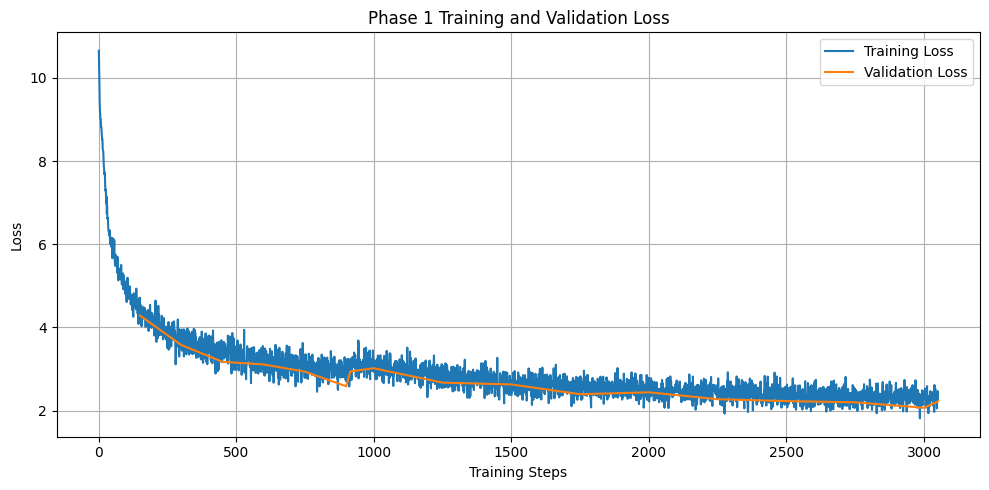

Loss plot saved to:
/kaggle/working/cs781_phase1/training_validation_loss.png


In [48]:
import matplotlib.pyplot as plt

# logs = trainer.state.log_history
logs = history

train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

# for log in logs:
#     if ("loss" in log and "step" in log):
#         train_steps.append(log["step"])
#         train_loss.append(log["loss"])
#     if ("eval_loss" in log and "step" in log):
#         eval_steps.append(log["step"])
#         eval_loss.append(log["eval_loss"])

for step, loss, _ in logs['train']:
    train_steps.append(step)
    train_loss.append(loss)
for step, loss, _ in logs["val"]:
    eval_steps.append(step)
    eval_loss.append(loss)

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [43]:
# trainer.save_model(MODEL_OUTPUT_DIR)
# tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

# print("Final model saved to:")
# print(MODEL_OUTPUT_DIR)

## 15. Push Model to Hugging Face Hub

In [44]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [51]:
from huggingface_hub import hf_hub_download

test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json: 0.00B [00:00, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [52]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


In [66]:
import json
import ijson
from tqdm import tqdm

saved_examples = []
example_id = 1

with open(test_file_path, "r", encoding="utf-8") as f:
    records = json.load(f)

    for data in tqdm(records.values()):
        # print(data['text'])
        if example_id > 4:
            break

        saved_examples.append({
            "id": example_id,
            "source": "test",
            "data": data['text']
        })

        example_id += 1

with open("test_examples_1_to_4.json", "w", encoding="utf-8") as f:
    json.dump(saved_examples, f, indent=2, ensure_ascii=False)


  0%|          | 4/1000 [00:00<00:00, 40427.03it/s]


## 18. Load Final Model for Generation

In [49]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generation_model = model.to(device)
generation_model.eval()
# generation_model.config.use_cache = True

print("Device:", device)
print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")

Device: cuda
Parameters: 152.13M


In [126]:
# with torch.no_grad():
#     a = torch.tensor([val_tokens[0][:300]], device=DEVICE)
#     la, _, _ = generation_model(a, last_only=True)                                   # unpadded, fp32
#     pad_n = 37
#     b = torch.cat([torch.zeros(1, pad_n, dtype=torch.long, device=DEVICE), a], dim=1)
#     m = torch.cat([torch.zeros(1, pad_n), torch.ones(1, a.size(1))], dim=1).to(DEVICE)
#     lb, _, _ = generation_model(b, attention_mask=m, last_only=True)                 # left-padded + masked
# print("max |logit diff| padded vs unpadded:", (la - lb).abs().max().item())

## 21. Save prediction.json

In [56]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1/prediction.json


## 22. Create CodaBench Submission ZIP

In [57]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1/submission.zip


In [1]:
!zip -r best_models.zip checkpoints -i "*_best.pt"

  adding: checkpoints/mla-rope-moe_best.pt (deflated 7%)
  adding: checkpoints/gqa-sinusoidal-moe_best.pt (deflated 7%)
  adding: checkpoints/abl_mla_rope_moe_best.pt (deflated 7%)
  adding: checkpoints/mla-sinusoidal-moe_best.pt (deflated 7%)
  adding: checkpoints/gqa-rope-moe_best.pt (deflated 7%)
  adding: checkpoints/abl_gqa_sin_moe_best.pt (deflated 7%)
  adding: checkpoints/abl_gqa_rope_moe_best.pt (deflated 7%)
  adding: checkpoints/abl_mla_sin_moe_best.pt (deflated 7%)


# Phase 2 - L-NER

In [3]:
!cp -rv ../input/datasets/pritam0289/phase1-models/ ./ 

'../input/datasets/pritam0289/phase1-models/' -> './phase1-models'
'../input/datasets/pritam0289/phase1-models/tokenizer.pkl' -> './phase1-models/tokenizer.pkl'
'../input/datasets/pritam0289/phase1-models/best_models' -> './phase1-models/best_models'
'../input/datasets/pritam0289/phase1-models/best_models/abl_gqa_rope_moe_best.pt' -> './phase1-models/best_models/abl_gqa_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/abl_gqa_sin_moe_best.pt' -> './phase1-models/best_models/abl_gqa_sin_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/abl_mla_sin_moe_best.pt' -> './phase1-models/best_models/abl_mla_sin_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/abl_mla_rope_moe_best.pt' -> './phase1-models/best_models/abl_mla_rope_moe_best.pt'


In [4]:
!ls

phase1-models  state.db


In [13]:
with open("./phase1-models/tokenizer.pkl", "rb") as f:
        tokenizer = pickle.load(f)

In [14]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


def get_device():
    """
      Return the computing device used in the current session.
    """
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = get_device()
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Using device: cuda
Tesla T4


In [75]:
import os, re, json, math, time, copy, random, zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm

# ---------------------------- configuration ----------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
NUM_WORKERS = 3
# DEVICE = globals().get(
#     "DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu")
# )

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
    
HF_REPO = globals().get(
    "HF_REPO", globals().get("HF_DATASET_REPO", "Exploration-Lab/CS-781-Capstone")
)
HF_TOKEN = globals().get("HF_TOKEN", os.environ.get("HF_TOKEN"))

WIN = 512
STRIDE = 256
BATCH_SIZE = 4
EVAL_BATCH_SIZE = 4
EPOCHS = {
    "full_ft": 13,
    "partial_top3": 10,
    "lora_r8": 10,
    "lorma_r8": 10,
    "adapter64": 10,
    "kd_student": 10,
    "student_noKD": 10,
}
LR = {
    "full_ft": 5e-5,
    "partial_top3": 1e-4,
    "lora_r8": 1e-3,
    "lorma_r8": 1e-3,
    "adapter64": 1e-3,
    "kd_student": 1e-4,
    "student_noKD": 1e-4,
}
HEAD_LR = 1e-3
WEIGHT_DECAY = 0.01
CAUSAL = False  # False: bidirectional NER attention; True: retain causal attention
KD_T = 2.0
KD_ALPHA = 0.5
ADAPTER_DIM = 64
LORA_R = 8
TOP_K_BLOCKS = 3
KD_KEEP_BLOCKS = [0, 2, 4, 7]

PHASE1_CKPT_DIR = "/kaggle/working/phase1-models/best_models"
OUT = "/kaggle/working/lner_runs"
os.makedirs(OUT, exist_ok=True)

VARIANTS = [
    "gqa_rope_moe",
    "mla_rope_moe",
    "gqa_sin_moe",
    "mla_sin_moe",
]
BASE = dict(
    vocab_size=30000, max_seq_len=2048, d_model=768, n_layers=16, n_heads=8, n_kv_heads=2,
    dropout=0.0, bias=False, tie_embeddings=True, d_ff=2048,
    q_lora_rank=384, kv_lora_rank=192, qk_nope_head_dim=80, qk_rope_head_dim=16, v_head_dim=96,
)
MOE = dict(ffn_type="moe", first_k_dense_layers=2, n_experts=8, top_k=2, n_shared_experts=1,
           expert_d_ff=512, aux_loss_coef=0.01)

CONFIGS = {
    "gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "mla_rope_moe": LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="rope"),
    "gqa_sin_moe":  LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="sinusoidal"),
    "mla_sin_moe":  LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="sinusoidal"),
}

assert "CONFIGS" in globals(), "Run the Phase-1 CONFIGS cell first."
assert "DecoderLM" in globals(), "Run the Phase-1 model-definition cells first."
assert "tokenizer" in globals(), "Load the trained Phase-1 tokenizer first."
assert all(v in CONFIGS for v in VARIANTS), "One or more expected variants are missing from CONFIGS."

# AMP selection compatible with Kaggle T4/A100 and CPU.
USE_AMP = DEVICE.type == "cuda"
if USE_AMP:
    AMP_DTYPE = (
        torch.bfloat16
        if torch.cuda.is_bf16_supported()
        else torch.float16
    )
else:
    AMP_DTYPE = torch.float32
USE_SCALER = USE_AMP and AMP_DTYPE == torch.float16

def autocast_context():
    return torch.autocast(
        device_type=DEVICE.type,
        dtype=AMP_DTYPE,
        enabled=USE_AMP
    )

USE_AMP = DEVICE.type == "cuda"

if USE_AMP:
    AMP_DTYPE = (
        torch.bfloat16
        if torch.cuda.is_bf16_supported()
        else torch.float16
    )
else:
    AMP_DTYPE = torch.float32

USE_SCALER = USE_AMP and AMP_DTYPE == torch.float16

print("Device:", DEVICE, "| AMP:", USE_AMP, AMP_DTYPE)

print("Device:", DEVICE, "| AMP:", USE_AMP, AMP_DTYPE)
print("Phase-1 checkpoint directory:", PHASE1_CKPT_DIR)
print("Phase-2 output directory:", OUT)

GPU: Tesla T4
GPU memory (GB): 14.56
Device: cuda | AMP: True torch.bfloat16
Device: cuda | AMP: True torch.bfloat16
Phase-1 checkpoint directory: /kaggle/working/phase1-models/best_models
Phase-2 output directory: /kaggle/working/lner_runs


In [16]:

# ---------------------------- model/tokenizer loaders ----------------------------

def load_tokenizer():
    """Uses the tokenizer object loaded by Phase 1; never retrains it."""
    tok = globals().get("tokenizer")
    if tok is None:
        raise RuntimeError("Phase-1 tokenizer is not loaded.")
    for attr in ("pat", "ranks", "merged_map", "stoi", "itos", "encode", "decode"):
        if not hasattr(tok, attr):
            raise TypeError(f"Phase-1 tokenizer lacks required attribute {attr!r}.")
    return tok

tokenizer = load_tokenizer()

def phase1_checkpoint_path(variant):
    # Phase-1 Cell 41 saves checkpoints/<tag>.pt.
    candidates = [
        os.path.join(PHASE1_CKPT_DIR, f"abl_{variant}_best.pt"),
        os.path.join(PHASE1_CKPT_DIR, f"{variant}_best.pt"),
        os.path.join(PHASE1_CKPT_DIR, f"abl_{variant}.pt"),
        os.path.join(PHASE1_CKPT_DIR, f"{variant}.pt"),
        os.path.join("/kaggle/working", PHASE1_CKPT_DIR, f"abl_{variant}_best.pt"),
    ]
    for p in candidates:
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        f"No Phase-1 checkpoint found for {variant}. Checked:\n" + "\n".join(candidates)
        + "\nSet PHASE1_CKPT_DIR to the directory containing your saved Phase-1 .pt files."
    )

def load_phase1_model(variant, checkpoint_path=None):
    """Rebuild the exact Phase-1 architecture and load its trained weights."""
    if variant not in CONFIGS:
        raise ValueError(f"Unknown variant {variant}; available: {list(CONFIGS)}")
    path = checkpoint_path or phase1_checkpoint_path(variant)
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model = DecoderLM(CONFIGS[variant])
    state = ckpt["model"] if isinstance(ckpt, dict) and "model" in ckpt else ckpt
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    model.load_state_dict(state, strict=True)
    model.to(DEVICE)
    print(f"Loaded Phase-1 {variant} from {path}")
    return model

In [17]:

# ---------------------------- dataset loading ----------------------------

def dl(name):
    if not HF_TOKEN:
        raise RuntimeError(
            "HF_TOKEN is not available. Run your Phase-1 Hugging Face login cell first."
        )
    return hf_hub_download(
        repo_id=HF_REPO,
        filename=f"Phase_2_LNER/{name}",
        repo_type="dataset",
        token=HF_TOKEN
    )

with open(dl("Train/labels.txt"), encoding="utf-8") as f:
    LABELS = [line.strip() for line in f if line.strip()]

BIO = ["O"] + [f"{p}-{label}" for label in LABELS for p in ("B", "I")]
L2I = {label: i for i, label in enumerate(BIO)}
I2L = {i: label for label, i in L2I.items()}
NL = len(BIO)

def load_fold(k):
    with open(dl(f"Train/fold{k}-text.json"), encoding="utf-8") as f:
        texts = json.load(f)
    with open(dl(f"Train/fold{k}-gold.json"), encoding="utf-8") as f:
        gold = json.load(f)

    text_by_id = {str(k): v for k, v in texts.items()}
    entities = {}
    for doc_id in text_by_id:
        rec = gold.get(doc_id, gold.get(int(doc_id)) if doc_id.isdigit() else None)
        if isinstance(rec, dict):
            rec = rec.get("entities", [])
        parsed = []
        for e in rec or []:
            if isinstance(e, dict):
                start = e.get("start", e.get("start_offset"))
                end = e.get("end", e.get("end_offset"))
                label = e.get("label", e.get("type"))
                text_value = e.get("text")
            else:
                start, end, label = e[:3]
                text_value = e[3] if len(e) > 3 else None
            parsed.append((int(start), int(end), label, text_value))
        entities[doc_id] = parsed
    return text_by_id, entities

train_texts, train_entities = load_fold(1)
val_texts, val_entities = load_fold(2)


print("Labels:", LABELS)
print("Train documents:", len(train_texts), "| validation documents:", len(val_texts))


labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

Labels: ['APP', 'RESP', 'A.COUNSEL', 'R.COUNSEL', 'JUDGE', 'WIT', 'AUTH', 'COURT', 'STAT', 'PREC', 'DATE', 'CASENO']
Train documents: 35 | validation documents: 35


In [18]:
# ---------------------------- tokenizer offsets / BIO alignment ----------------------------
# Use the labels loaded from your dataset
BIO = ["O"] + [
    f"{prefix}-{label}"
    for label in LABELS
    for prefix in ("B", "I")
]

l2i = {label: idx for idx, label in enumerate(BIO)}
NL = len(BIO)

print("Number of BIO classes:", NL)
print("Example mappings:", {k: l2i[k] for k in BIO[:5]})
def encode_with_offsets(text, tok=tokenizer):
    """
    Encode text using the existing BPE tokenizer and return:
      ids: token IDs
      offsets: (start, end) character offsets into the original text

    Offsets use Python's [start, end) convention.
    """
    ids = []
    offsets = []

    for match in tok.pat.finditer(text):
        word = match.group()
        if not word:
            continue

        # Split the word into UTF-8 bytes, matching the tokenizer's BPE.
        word_bytes = word.encode("utf-8")
        pieces = [
            (bytes([b]), i, i + 1)
            for i, b in enumerate(word_bytes)
        ]

        # Map every UTF-8 byte to its original character index.
        byte_to_char = []
        for char_i, char in enumerate(word):
            byte_to_char.extend([char_i] * len(char.encode("utf-8")))

        # Apply the same ranked BPE merge procedure as the tokenizer.
        while len(pieces) > 1:
            best_i = -1
            best_rank = float("inf")

            for i in range(len(pieces) - 1):
                pair = (pieces[i][0], pieces[i + 1][0])
                rank = tok.ranks.get(pair, float("inf"))

                if rank < best_rank:
                    best_i = i
                    best_rank = rank

            if best_i == -1:
                break

            left = pieces[best_i]
            right = pieces[best_i + 1]

            pieces[best_i:best_i + 2] = [
                (left[0] + right[0], left[1], right[2])
            ]

        # Convert each merged piece's byte range to character offsets.
        for piece, byte_start, byte_end in pieces:
            start = match.start() + byte_to_char[byte_start]
            end = match.start() + byte_to_char[byte_end - 1] + 1

            # Remove leading whitespace from the token's character span,
            # while preserving the original text's coordinate system.
            while start < end and text[start].isspace():
                start += 1

            token_id = tok.stoi.get(piece, tok.stoi["<unk>"])

            ids.append(token_id)
            offsets.append((start, end))

    return ids, offsets

def token_labels(entities, offsets):
    """
    entities: [(start, end, label, text), ...]
    offsets: [(start, end), ...]

    Returns:
      y: BIO label ID for each token
      exact: number of entities with exact token boundaries
    """
    y = [l2i["O"]] * len(offsets)
    exact = 0

    for s, e, label, _ in entities:
        if not (0 <= s < e):
            continue

        overlapping = [
            i for i, (a, b) in enumerate(offsets)
            if a < b and a < e and b > s
        ]

        if not overlapping:
            continue

        first = overlapping[0]
        last = overlapping[-1]

        if offsets[first][0] == s and offsets[last][1] == e:
            exact += 1

        # Assign BIO labels to the overlapping tokens.
        y[first] = l2i[f"B-{label}"]

        for i in overlapping[1:]:
            y[i] = l2i[f"I-{label}"]

    return y, exact

def build_docs(texts, entities, desc):
    docs = {}
    for doc_id, text in tqdm(texts.items(), desc=desc):
        ids, offsets = encode_with_offsets(text)
        tags, exact = token_labels(entities[doc_id], offsets)
        docs[doc_id] = {
            "text": text, "ids": ids, "offs": offsets, "y": tags,
            "gold": [(s, e, lab) for s, e, lab, _ in entities[doc_id]],
            "exact": exact
        }
    return docs

train_docs = build_docs(train_texts, train_entities, "Encode train")
val_docs = build_docs(val_texts, val_entities, "Encode validation")
n_gold_train = sum(len(x["gold"]) for x in train_docs.values())
n_exact_train = sum(x["exact"] for x in train_docs.values())
print(f"Exact token-boundary entities (train): {n_exact_train}/{n_gold_train}")



Number of BIO classes: 25
Example mappings: {'O': 0, 'B-APP': 1, 'I-APP': 2, 'B-RESP': 3, 'I-RESP': 4}


Encode train:   0%|          | 0/35 [00:00<?, ?it/s]

Encode validation:   0%|          | 0/35 [00:00<?, ?it/s]

Exact token-boundary entities (train): 4049/4120


In [19]:
from sklearn.model_selection import train_test_split

# 1. Merge training and validation documents
all_docs = {**train_docs, **val_docs}

# 2. Extract gold annotations directly from the merged documents
all_gold = {
    doc_id: doc["gold"]
    for doc_id, doc in all_docs.items()
}

# 3. Split by document ID
doc_ids = list(all_docs.keys())

train_ids, val_ids = train_test_split(
    doc_ids,
    test_size=0.2,
    random_state=SEED
)

# 4. Create the new datasets
train_docs = {doc_id: all_docs[doc_id] for doc_id in train_ids}
val_docs = {doc_id: all_docs[doc_id] for doc_id in val_ids}

# 5. Update validation gold annotations
gold_v = {doc_id: all_gold[doc_id] for doc_id in val_ids}

print(f"Training documents: {len(train_docs)}")
print(f"Validation documents: {len(val_docs)}")
print(f"Total documents: {len(train_docs) + len(val_docs)}")

Training documents: 56
Validation documents: 14
Total documents: 70


In [50]:

# ---------------------------- BIO decoding and strict metrics ----------------------------

def viterbi(logp):
    T = logp.shape[0]
    if T == 0:
        return []
    allow = np.zeros((NL, NL), dtype=bool)
    for prev in range(NL):
        for cur in range(NL):
            name = BIO[cur]
            allow[prev, cur] = not (
                name.startswith("I-")
                and not (BIO[prev] != "O" and BIO[prev][2:] == name[2:])
            )
    trans = np.where(allow, 0.0, -1e9)
    start = np.array([0.0 if not BIO[c].startswith("I-") else -1e9 for c in range(NL)])
    dp = start + logp[0]
    back = np.zeros((T, NL), dtype=np.int64)
    for t in range(1, T):
        scores = dp[:, None] + trans
        back[t] = scores.argmax(axis=0)
        dp = scores.max(axis=0) + logp[t]
    path = [int(dp.argmax())]
    for t in range(T - 1, 0, -1):
        path.append(int(back[t, path[-1]]))
    return path[::-1]

def tags_to_spans(tags, offsets):
    spans, current = [], None
    for tag_id, (start, end) in zip(tags, offsets):
        if start == end:
            continue
        name = BIO[int(tag_id)]
        if name == "O":
            if current is not None:
                spans.append(tuple(current))
                current = None
        elif name.startswith("B-") or current is None or current[2] != name[2:]:
            if current is not None:
                spans.append(tuple(current))
            current = [start, end, name[2:]]
        else:
            current[1] = end
    if current is not None:
        spans.append(tuple(current))
    return spans

def strict_prf(gold, pred):
    tp, fp, fn = Counter(), Counter(), Counter()
    for doc_id in set(gold) | set(pred):
        G = set(tuple(x) for x in gold.get(doc_id, []))
        P = set(tuple(x) for x in pred.get(doc_id, []))
        for ent in P:
            (tp if ent in G else fp)[ent[2]] += 1
        for ent in G - P:
            fn[ent[2]] += 1
    per = {}
    for label in LABELS:
        if tp[label] + fp[label] + fn[label] == 0:
            continue
        p = tp[label] / max(1, tp[label] + fp[label])
        r = tp[label] / max(1, tp[label] + fn[label])
        f = 2 * p * r / max(1e-12, p + r)
        per[label] = (p, r, f, tp[label] + fn[label])
    mean = lambda i: float(np.mean([v[i] for v in per.values()])) if per else 0.0
    return {"P": mean(0), "R": mean(1), "F1": mean(2), "per_label": per}

def error_analysis(gold, pred):
    counts = Counter()
    for doc_id in set(gold) | set(pred):
        G = set(tuple(x) for x in gold.get(doc_id, []))
        P = set(tuple(x) for x in pred.get(doc_id, []))
        for x in P:
            if x in G:
                counts["exact"] += 1
            elif any((g[0], g[1]) == (x[0], x[1]) for g in G):
                counts["label_confusion"] += 1
            elif any(g[2] == x[2] and g[0] < x[1] and x[0] < g[1] for g in G):
                counts["boundary_error"] += 1
            else:
                counts["false_positive"] += 1
        for g in G - P:
            if not any(p[0] < g[1] and g[0] < p[1] for p in P):
                counts["missed(FN)"] += 1
    return dict(counts)

# def show(res, title=""):
#     print(f"{title} | macro P {res['P']:.4f} R {res['R']:.4f} F1 {res['F1']:.4f}")
#     for label, (p, r, f, n) in res["per_label"].items():
#         print(f"  {label:15s} P {p:.3f} R {r:.3f} F1 {f:.3f} n={n}")
def show(res, title):
    print(
        f"{title} | "
        f"macro P {float(res['P']):.4f} "
        f"R {float(res['R']):.4f} "
        f"F1 {float(res['F1']):.4f}"
    )

    # Support both possible per-class result formats.
    per_label = res.get("per_label", res.get("per", {}))

    for label, values in per_label.items():
        # Expected format: (precision, recall, F1, support)
        if isinstance(values, dict):
            p = values.get("P", values.get("precision"))
            r = values.get("R", values.get("recall"))
            f1 = values.get("F1", values.get("f1"))
            n = values.get("n", values.get("support", 0))
        else:
            p, r, f1, n = values

        print(
            f"  {label:15s} "
            f"P {float(p):.3f} "
            f"R {float(r):.3f} "
            f"F1 {float(f1):.3f} "
            f"n={n}"
        )

gold_v = {doc_id: x["gold"] for doc_id, x in val_docs.items()}
oracle = {doc_id: tags_to_spans(x["y"], x["offs"]) for doc_id, x in val_docs.items()}
show(strict_prf(gold_v, oracle), "ORACLE (token alignment upper bound)")


ORACLE (token alignment upper bound) | macro P 0.9777 R 0.9777 F1 0.9777
  APP             P 0.934 R 0.934 F1 0.934 n=61
  RESP            P 1.000 R 1.000 F1 1.000 n=66
  A.COUNSEL       P 1.000 R 1.000 F1 1.000 n=26
  R.COUNSEL       P 1.000 R 1.000 F1 1.000 n=21
  JUDGE           P 1.000 R 1.000 F1 1.000 n=64
  WIT             P 1.000 R 1.000 F1 1.000 n=62
  AUTH            P 0.974 R 0.974 F1 0.974 n=190
  COURT           P 1.000 R 1.000 F1 1.000 n=136
  STAT            P 0.948 R 0.948 F1 0.948 n=212
  PREC            P 0.876 R 0.876 F1 0.876 n=201
  DATE            P 1.000 R 1.000 F1 1.000 n=315
  CASENO          P 1.000 R 1.000 F1 1.000 n=161


In [38]:
def decode_bio(tag_ids, offsets):
    spans = []
    current = None

    for tag_id, (start, end) in zip(tag_ids, offsets):
        if start == end:
            continue

        tag = id_to_label[int(tag_id)]

        if tag == "O":
            if current is not None:
                spans.append(tuple(current))
                current = None
            continue

        prefix, label = tag.split("-", 1)

        if (
            prefix == "B"
            or current is None
            or current[2] != label
        ):
            if current is not None:
                spans.append(tuple(current))
            current = [start, end, label]
        else:
            current[1] = end

    if current is not None:
        spans.append(tuple(current))

    return spans


def strict_prf(gold, pred):
    tp, fp, fn = Counter(), Counter(), Counter()

    for doc_id in set(gold) | set(pred):
        G = set(tuple(x) for x in gold.get(doc_id, []))
        P = set(tuple(x) for x in pred.get(doc_id, []))

        for entity in P:
            (tp if entity in G else fp)[entity[2]] += 1

        for entity in G - P:
            fn[entity[2]] += 1

    per_label = {}

    for label in LABELS:
        if tp[label] + fp[label] + fn[label] == 0:
            continue

        p = tp[label] / max(1, tp[label] + fp[label])
        r = tp[label] / max(1, tp[label] + fn[label])
        f = 2 * p * r / max(1e-12, p + r)

        per_label[label] = {
            "P": p, "R": r, "F1": f,
            "support": tp[label] + fn[label]
        }

    if not per_label:
        return {"P": 0.0, "R": 0.0, "F1": 0.0, "per_label": {}}

    return {
        "P": float(np.mean([x["P"] for x in per_label.values()])),
        "R": float(np.mean([x["R"] for x in per_label.values()])),
        "F1": float(np.mean([x["F1"] for x in per_label.values()])),
        "per_label": per_label
    }


def show_metrics(result, name=""):
    print(
        f"{name} | macro P={result['P']:.4f} "
        f"R={result['R']:.4f} F1={result['F1']:.4f}"
    )
    for label, values in result["per_label"].items():
        print(
            f"  {label:15s} P={values['P']:.3f} "
            f"R={values['R']:.3f} F1={values['F1']:.3f} "
            f"n={values['support']}"
        )

In [39]:

# ---------------------------- windows and batches ----------------------------

PAD = tokenizer.stoi["<pad>"]
BOS = tokenizer.stoi["<s>"]

def make_windows(n, win=WIN, step=STRIDE):
    if n <= win:
        return [(0, n)]
    starts = list(range(0, n - win + 1, step))
    if starts[-1] + win < n:
        starts.append(n - win)
    return [(s, min(s + win, n)) for s in starts]

def make_items(docs, step=STRIDE):
    items = []
    for doc_id, doc in docs.items():
        for a, b in make_windows(len(doc["ids"]), WIN, step):
            items.append({
                "doc_id": doc_id, "start": a, "end": b,
                "ids": [BOS] + doc["ids"][a:b],
                "y": [-100] + doc["y"][a:b]
            })
    return items

def collate(batch):
    max_len = max(len(item["ids"]) for item in batch)
    ids = torch.full((len(batch), max_len), PAD, dtype=torch.long)
    labels = torch.full((len(batch), max_len), -100, dtype=torch.long)
    attn = torch.zeros((len(batch), max_len), dtype=torch.bool)
    for i, item in enumerate(batch):
        n = len(item["ids"])
        ids[i, :n] = torch.tensor(item["ids"], dtype=torch.long)
        labels[i, :n] = torch.tensor(item["y"], dtype=torch.long)
        attn[i, :n] = True
    return ids, labels, attn


In [40]:

# ---------------------------- hidden-state backbone / NER head ----------------------------

class Adapter(nn.Module):
    def __init__(self, d_model, rank):
        super().__init__()
        self.down = nn.Linear(d_model, rank)
        self.up = nn.Linear(rank, d_model)
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)

    def forward(self, x):
        return x + self.up(F.gelu(self.down(x)))

class NERBackbone(nn.Module):
    """
    Calls the actual Phase-1 TransformerBlock API.
    The language-model vocabulary head is bypassed; token hidden states are used.
    """
    def __init__(self, lm, causal=CAUSAL, adapter_dim=0):
        super().__init__()
        self.lm = lm
        self.causal = causal
        self.dim = lm.cfg.d_model
        self.adapters = (
            nn.ModuleList([Adapter(self.dim, adapter_dim) for _ in lm.blocks])
            if adapter_dim else None
        )

    def forward(self, input_ids, attention_mask):
        B, T = input_ids.shape
        assert T <= self.lm.cfg.max_seq_len, (
            f"Window length {T} exceeds model max_seq_len={self.lm.cfg.max_seq_len}"
        )
        # Right padding. For bidirectional attention, bool True means allowed
        # keys in scaled_dot_product_attention.
        positions = torch.arange(T, device=input_ids.device)
        x = self.lm.tok_emb(input_ids)
        if self.lm.sin_emb is not None:
            x = x * math.sqrt(self.lm.cfg.d_model) + self.lm.sin_emb.pe[positions].to(x.dtype)
        x = self.lm.drop(x)

        if self.causal:
            attn_mask = None
        else:
            attn_mask = attention_mask[:, None, None, :].bool()

        aux_total = x.new_zeros(())
        for i, block in enumerate(self.lm.blocks):
            x, aux, _ = block(
                x,
                rope=self.lm.rope,
                positions=positions,
                kv_cache=None,
                attn_mask=attn_mask
            )
            aux_total = aux_total + aux
            if self.adapters is not None:
                x = self.adapters[i](x)

        return self.lm.final_norm(x), aux_total

class NERModel(nn.Module):
    def __init__(self, lm, head="linear", dropout=0.1, causal=CAUSAL, adapter_dim=0):
        super().__init__()
        self.backbone = NERBackbone(lm, causal=causal, adapter_dim=adapter_dim)
        d = self.backbone.dim
        self.drop = nn.Dropout(dropout)
        if head == "linear":
            self.head = nn.Linear(d, NL)
        elif head == "mlp":
            self.head = nn.Sequential(
                nn.Linear(d, d), nn.GELU(), nn.Dropout(dropout), nn.Linear(d, NL)
            )
        else:
            raise ValueError("head must be 'linear' or 'mlp'")

    def forward(self, input_ids, attention_mask):
        hidden, aux_loss = self.backbone(input_ids, attention_mask)
        logits = self.head(self.drop(hidden))
        return logits, aux_loss


# ---------------------------- LoRA and LoRMA ----------------------------

class LoRALinear(nn.Module):
    """Additive low-rank update: base(x) + scale * B(A(x))."""
    def __init__(self, base, r=8, alpha=16):
        super().__init__()
        self.base = base
        self.scale = alpha / r
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))

    def forward(self, x):
        return self.base(x) + (x @ self.A.t() @ self.B.t()) * self.scale

class LoRMALinear(nn.Module):
    """Multiplicative output-side low-rank update: y + scale * B(A(y))."""
    def __init__(self, base, r=8, alpha=16):
        super().__init__()
        self.base = base
        self.scale = alpha / r
        self.A = nn.Parameter(torch.randn(r, base.out_features) / math.sqrt(base.out_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))

    def forward(self, x):
        y = self.base(x)
        return y + (y @ self.A.t() @ self.B.t()) * self.scale


In [41]:

# Adapt attention projections only. Routed experts remain frozen and untouched.
LORA_TARGETS = {
    "q_proj", "k_proj", "v_proj", "o_proj",
    "q_down", "q_up", "kv_down", "kv_up", "k_rope_proj"
}

def inject_low_rank(lm, wrapper_cls, r=8, alpha=16):
    for block in lm.blocks:
        for parent_name, parent in list(block.named_modules()):
            if "experts" in parent_name.split(".") or "shared" in parent_name.split("."):
                continue
            for child_name, child in list(parent.named_children()):
                if child_name in LORA_TARGETS and isinstance(child, nn.Linear):
                    setattr(parent, child_name, wrapper_cls(child, r=r, alpha=alpha))


# ---------------------------- builders for methods ----------------------------

def build_model(variant, method, head="linear", r=LORA_R, k_top=TOP_K_BLOCKS):
    lm = load_phase1_model(variant)

    if method in ("lora", "lorma", "adapter", "partial", "kd", "student_noKD"):
        for p in lm.parameters():
            p.requires_grad = False

    adapter_dim = ADAPTER_DIM if method == "adapter" else 0

    if method == "partial":
        for block in lm.blocks[-k_top:]:
            for p in block.parameters():
                p.requires_grad = True
        for p in lm.final_norm.parameters():
            p.requires_grad = True

    elif method == "lora":
        inject_low_rank(lm, LoRALinear, r=r, alpha=2*r)
        for name, p in lm.named_parameters():
            if ".A" in name or ".B" in name:
                p.requires_grad = True

    elif method == "lorma":
        inject_low_rank(lm, LoRMALinear, r=r, alpha=2*r)
        for name, p in lm.named_parameters():
            if ".A" in name or ".B" in name:
                p.requires_grad = True

    model = NERModel(
        lm,
        head=head,
        dropout=0.1,
        causal=CAUSAL,
        adapter_dim=adapter_dim
    )

    # For adapter mode, the adapter parameters are new and trainable while LM is frozen.
    if method == "adapter":
        for p in model.backbone.lm.parameters():
            p.requires_grad = False
        for p in model.backbone.adapters.parameters():
            p.requires_grad = True

    # In all PEFT modes, train the NER classification head.
    for p in model.head.parameters():
        p.requires_grad = True

    return model.to(DEVICE)

def n_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# ---------------------------- inference and evaluation ----------------------------

@torch.no_grad()
def predict_docs(model, docs, decode="viterbi", batch_size=EVAL_BATCH_SIZE):
    model.eval()
    predictions = {}
    for doc_id, doc in tqdm(docs.items(), desc="Predict"):
        n = len(doc["ids"])
        if n == 0:
            predictions[doc_id] = []
            continue
        acc = np.zeros((n, NL), dtype=np.float32)
        cnt = np.zeros(n, dtype=np.float32)
        windows = make_windows(n, WIN, WIN // 2)

        for start in range(0, len(windows), batch_size):
            chunk = windows[start:start + batch_size]
            batch = [
                {"ids": [BOS] + doc["ids"][a:b], "y": [-100] * (b-a+1)}
                for a, b in chunk
            ]
            ids, _, attn = collate(batch)
            ids, attn = ids.to(DEVICE), attn.to(DEVICE)
            with autocast_context():
                logits, _ = model(ids, attn)
            log_probs = logits.float().log_softmax(-1).cpu().numpy()
            for i, (a, b) in enumerate(chunk):
                acc[a:b] += log_probs[i, 1:b-a+1]
                cnt[a:b] += 1

        logp = acc / np.maximum(cnt[:, None], 1.0)
        tags = viterbi(logp) if decode == "viterbi" else logp.argmax(-1).tolist()
        predictions[doc_id] = tags_to_spans(tags, doc["offs"])
    return predictions

def evaluate(model, docs, decode="viterbi"):
    pred = predict_docs(model, docs, decode=decode)
    gold = {doc_id: doc["gold"] for doc_id, doc in docs.items()}
    return strict_prf(gold, pred), pred



In [42]:

# ---------------------------- training with resumable checkpoints ----------------------------

def class_weights(docs, power=0.5, cap=10.0):
    counts = np.bincount(
        np.concatenate([doc["y"] for doc in docs.values()]),
        minlength=NL
    ).astype(np.float64) + 1.0
    weights = np.clip((counts[0] / counts) ** power, 0, cap)
    weights[0] = 1.0
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)

CW = class_weights(train_docs)

def checkpoint_paths(name):
    return (
        os.path.join(OUT, f"{name}_best.pt"),
        os.path.join(OUT, f"{name}_last.pt"),
        os.path.join(OUT, f"{name}_metadata.json"),
    )

def save_state(path, model, optimizer, epoch, best_f1, history, step=0, scaler=None):
    payload = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict() if optimizer is not None else None,
        "scaler": scaler.state_dict() if scaler is not None else None,
        "epoch": epoch,
        "step": step,
        "best_f1": best_f1,
        "history": history,
        "bio_labels": BIO,
        "labels": LABELS,
    }
    torch.save(payload, path)

def load_state(path, model, optimizer=None, scaler=None):
    state = torch.load(path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(state["model"], strict=True)
    if optimizer is not None and state.get("optimizer") is not None:
        optimizer.load_state_dict(state["optimizer"])
    if scaler is not None and state.get("scaler") is not None:
        scaler.load_state_dict(state["scaler"])
    return state

def train(
    model, name, epochs, lr, head_lr=HEAD_LR, batch_size=BATCH_SIZE,
    weight_decay=WEIGHT_DECAY, cw=CW, teacher=None, T=KD_T,
    alpha=KD_ALPHA, resume=True
):
    best_path, last_path, metadata_path = checkpoint_paths(name)
    items = make_items(train_docs)
    loader = DataLoader(
        items, batch_size=batch_size, shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
        collate_fn=collate
    )

    backbone_params = [
        p for n, p in model.named_parameters()
        if p.requires_grad and not n.startswith("head.")
    ]
    head_params = [
        p for n, p in model.named_parameters()
        if p.requires_grad and n.startswith("head.")
    ]
    groups = []
    if backbone_params:
        groups.append({"params": backbone_params, "lr": lr})
    if head_params:
        groups.append({"params": head_params, "lr": head_lr})
    optimizer = torch.optim.AdamW(groups, weight_decay=weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)

    start_epoch, best_f1, history = 0, -1.0, []
    if resume and os.path.isfile(last_path):
        state = load_state(last_path, model, optimizer, scaler)
        start_epoch = int(state.get("epoch", 0))
        best_f1 = float(state.get("best_f1", -1.0))
        history = state.get("history", [])
        print(f"[{name}] resuming from epoch {start_epoch}")

    t0 = time.time()
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    for epoch in range(start_epoch, epochs):
        model.train()
        if teacher is not None:
            teacher.eval()
        random.shuffle(items)
        # Shuffle DataLoader's dataset list too by recreating it for this epoch.
        loader = DataLoader(
            items, batch_size=batch_size, shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=(DEVICE.type == "cuda"),
            persistent_workers=(NUM_WORKERS > 0),
            collate_fn=collate
        )
        total_loss, batches = 0.0, 0

        for ids, y, attn in tqdm(loader, desc=f"{name} epoch {epoch+1}/{epochs}"):
            ids, y, attn = ids.to(DEVICE), y.to(DEVICE), attn.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP
            ):
                logits, aux = model(ids, attn)
                ce = F.cross_entropy(
                    logits.float().reshape(-1, NL),
                    y.reshape(-1),
                    weight=cw,
                    ignore_index=-100
                )
                loss = ce + model.backbone.lm.cfg.aux_loss_coef * aux

                if teacher is not None:
                    with torch.no_grad():
                        t_logits, _ = teacher(ids, attn)
                    selected = y != -100
                    if selected.any():
                        student_logp = F.log_softmax(logits.float()[selected] / T, dim=-1)
                        teacher_prob = F.softmax(t_logits.float()[selected] / T, dim=-1)
                        kd = F.kl_div(
                            student_logp, teacher_prob, reduction="batchmean"
                        ) * (T * T)
                        loss = alpha * loss + (1 - alpha) * kd

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], 1.0
            )
            scaler.step(optimizer)
            scaler.update()

            total_loss += float(loss.detach().item())
            batches += 1

        val_result, _ = evaluate(model, val_docs)
        avg_loss = total_loss / max(1, batches)
        history.append({
            "epoch": epoch + 1,
            "train_loss": avg_loss,
            "P": val_result["P"],
            "R": val_result["R"],
            "F1": val_result["F1"],
        })
        print(
            f"[{name}] epoch {epoch+1}/{epochs} loss={avg_loss:.4f} "
            f"| val P={val_result['P']:.4f} R={val_result['R']:.4f} "
            f"F1={val_result['F1']:.4f}"
        )

        if val_result["F1"] > best_f1:
            best_f1 = val_result["F1"]
            save_state(best_path, model, None, epoch + 1, best_f1, history)
            print("Saved best:", best_path)

        save_state(last_path, model, optimizer, epoch + 1, best_f1, history, scaler=scaler)

    # Restore best weights before returning.
    best_state = load_state(best_path, model)
    peak_gb = (
        torch.cuda.max_memory_allocated() / (1024**3)
        if DEVICE.type == "cuda" else float("nan")
    )
    with open(metadata_path, "w", encoding="utf-8") as f:
        json.dump({
            "name": name,
            "epochs_requested": epochs,
            "best_epoch": best_state.get("epoch"),
            "best_val_f1": best_f1,
            "bio_labels": BIO,
            "labels": LABELS,
            "causal": CAUSAL,
            "window": WIN,
            "stride": STRIDE,
        }, f, indent=2)
    return {
        "best_val_f1": best_f1,
        "train_sec": time.time() - t0,
        "peak_gb": peak_gb,
        "hist": history,
        "best_path": best_path,
        "last_path": last_path,
    }



In [43]:

# ---------------------------- test data and submission writer ----------------------------

def load_test_docs():
    with open(dl("Test/fold3-text.json"), encoding="utf-8") as f:
        texts = json.load(f)
    texts = {str(k): v for k, v in texts.items()}
    docs = {}
    for doc_id, text in tqdm(texts.items(), desc="Encode test"):
        ids, offs = encode_with_offsets(text)
        docs[doc_id] = {
            "text": text, "ids": ids, "offs": offs,
            "y": [0] * len(ids), "gold": []
        }
    return texts, docs

def write_test(model, name):
    test_texts, test_docs = load_test_docs()
    pred = predict_docs(model, test_docs)
    js = {
        doc_id: [
            [s, e, label, test_texts[doc_id][s:e]]
            for s, e, label in spans
        ]
        for doc_id, spans in pred.items()
    }
    json_path = os.path.join(OUT, f"prediction_{name}.json")
    zip_path = os.path.join(OUT, f"submission_{name}.zip")
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(js, f, ensure_ascii=False, indent=2)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(json_path, arcname="prediction.json")
    print("Wrote:", json_path)
    print("Wrote:", zip_path)
    return json_path, zip_path



In [77]:


# ---------------------------- one complete experiment ----------------------------

RESULTS, MODELS = {}, {}

def run_experiment(variant, method, epochs=None, lr=None, head="linear", resume=True):
    """
    method: full, partial, lora, lorma, adapter, kd, student_noKD
    Unique checkpoint names are created per variant and method.
    """
    name = f"{variant}__{method}"
    epochs = epochs or EPOCHS[method]
    lr = lr or LR[method]

    # Avoid silently retraining a completed run. Load best if already present.
    best_path, last_path, _ = checkpoint_paths(name)
    if os.path.isfile(best_path) and not os.path.isfile(last_path):
        print(f"[{name}] best checkpoint exists; loading without training.")
        model = build_model(variant, method, head=head)
        state = load_state(best_path, model)
        result, pred = evaluate(model, val_docs)
        info = {
            "best_val_f1": state.get("best_f1", result["F1"]),
            "train_sec": 0.0,
            "peak_gb": float("nan"),
            "hist": state.get("history", []),
        }
    else:
        model = build_model(variant, method, head=head)
        tot, tr = n_params(model)
        print(
            f"\n=== {name}: total {tot/1e6:.2f}M, trainable {tr/1e6:.2f}M "
            f"({100*tr/max(1,tot):.2f}%) ==="
        )
        info = train(
            model, name, epochs=epochs, lr=lr, resume=resume,
            teacher=None
        )
        result, pred = evaluate(model, val_docs)

    tot, tr = n_params(model)
    info.update({
        "variant": variant,
        "method": method,
        "total_M": tot / 1e6,
        "trainable_M": tr / 1e6,
        "P": result["P"],
        "R": result["R"],
        "F1": result["F1"],
        "per_label": result["per_label"],
        "errors": error_analysis(gold_v, pred),
    })
    RESULTS[name] = info
    MODELS[name] = model
    show(result, f"[{name}] FINAL VALIDATION")
    write_test(model, name)
    return model


In [45]:

# ---------------------------- knowledge distillation helpers ----------------------------

def build_kd_student(variant, keep=KD_KEEP_BLOCKS):
    """
    Build a 4-block student from selected pretrained Phase-1 blocks.
    Blocks are deep-copied from the original model so their original MoE/dense
    structure is preserved exactly (important for layer-specific FFN shapes).
    """
    teacher_lm = load_phase1_model(variant)
    if max(keep) >= len(teacher_lm.blocks):
        raise ValueError(f"KD_KEEP_BLOCKS {keep} exceeds model depth {len(teacher_lm.blocks)}")

    student_lm = copy.deepcopy(teacher_lm)
    student_lm.blocks = nn.ModuleList([
        copy.deepcopy(teacher_lm.blocks[i]) for i in keep
    ])
    # The forward method uses cfg.max_seq_len and cfg.aux_loss_coef; n_layers is
    # only construction metadata after the blocks have been copied.
    student_lm.cfg = copy.deepcopy(teacher_lm.cfg)
    student_lm.cfg.n_layers = len(keep)
    return student_lm.to(DEVICE)

def run_kd_experiment(variant, teacher_model, epochs=None, resume=True):
    method = "kd"
    name = f"{variant}__{method}"
    epochs = epochs or EPOCHS["kd_student"]
    best_path, last_path, _ = checkpoint_paths(name)

    student_lm = build_kd_student(variant)
    student = NERModel(student_lm, head="linear", dropout=0.1, causal=CAUSAL).to(DEVICE)
    # KD student is fully fine-tuned, as in the original Phase-2 experiment.
    for p in student.parameters():
        p.requires_grad = True

    if os.path.isfile(best_path) and not os.path.isfile(last_path):
        state = load_state(best_path, student)
        result, pred = evaluate(student, val_docs)
        info = {"best_val_f1": state.get("best_f1", result["F1"]), "train_sec": 0.0,
                "peak_gb": float("nan"), "hist": state.get("history", [])}
    else:
        tot, tr = n_params(student)
        print(f"\n=== {name}: total {tot/1e6:.2f}M, trainable {tr/1e6:.2f}M ===")
        info = train(
            student, name, epochs=epochs, lr=LR["kd_student"],
            resume=resume, teacher=teacher_model, T=KD_T, alpha=KD_ALPHA
        )
        result, pred = evaluate(student, val_docs)

    tot, tr = n_params(student)
    info.update({
        "variant": variant, "method": method,
        "total_M": tot / 1e6, "trainable_M": tr / 1e6,
        "P": result["P"], "R": result["R"], "F1": result["F1"],
        "per_label": result["per_label"], "errors": error_analysis(gold_v, pred),
    })
    RESULTS[name] = info
    MODELS[name] = student
    show(result, f"[{name}] FINAL VALIDATION")
    write_test(student, name)
    return student

def run_no_kd_control(variant, epochs=None, resume=True):
    method = "student_noKD"
    name = f"{variant}__{method}"
    epochs = epochs or EPOCHS[method]
    best_path, last_path, _ = checkpoint_paths(name)

    student_lm = build_kd_student(variant)
    student = NERModel(student_lm, head="linear", dropout=0.1, causal=CAUSAL).to(DEVICE)
    for p in student.parameters():
        p.requires_grad = True

    if os.path.isfile(best_path) and not os.path.isfile(last_path):
        state = load_state(best_path, student)
        result, pred = evaluate(student, val_docs)
        info = {"best_val_f1": state.get("best_f1", result["F1"]), "train_sec": 0.0,
                "peak_gb": float("nan"), "hist": state.get("history", [])}
    else:
        info = train(
            student, name, epochs=epochs, lr=LR["student_noKD"],
            resume=resume, teacher=None
        )
        result, pred = evaluate(student, val_docs)

    tot, tr = n_params(student)
    info.update({
        "variant": variant, "method": method,
        "total_M": tot / 1e6, "trainable_M": tr / 1e6,
        "P": result["P"], "R": result["R"], "F1": result["F1"],
        "per_label": result["per_label"], "errors": error_analysis(gold_v, pred),
    })
    RESULTS[name] = info
    MODELS[name] = student
    show(result, f"[{name}] FINAL VALIDATION")
    write_test(student, name)
    return student



In [67]:

# ---------------------------- full suite for ONE variant ----------------------------

def run_variant_suite(variant, run_kd=True):
    """
    Runs all original Phase-2 methods for this Phase-1 architecture:
      full FT, partial top-3, LoRA, LoRMA, adapters, KD, no-KD control.
    Checkpoints are kept per experiment so completed runs are not repeated.
    """
    print("\n" + "=" * 80)
    print("PHASE-2 VARIANT:", variant)
    print("=" * 80)

    # Exp 1: full fine-tuning; this is the KD teacher.
    teacher = run_experiment(variant, "full", epochs=EPOCHS["full_ft"], lr=LR["full_ft"])

    # Exp 2: partial fine-tuning, top three blocks.
    # run_experiment(variant, "partial", epochs=EPOCHS["partial_top3"], lr=LR["partial_top3"])

    # Exp 3: LoRA rank 8.
    # run_experiment(variant, "lora", epochs=EPOCHS["lora_r8"], lr=LR["lora_r8"])

    # Exp 4: LoRMA rank 8.
    # run_experiment(variant, "lorma", epochs=EPOCHS["lorma_r8"], lr=LR["lorma_r8"])

    # Exp 5: Houlsby-style adapters.
    # run_experiment(variant, "adapter", epochs=EPOCHS["adapter64"], lr=LR["adapter64"])

    # Exp 6: KD student + Exp 7: same student without KD.
    # if run_kd:
        # run_kd_experiment(variant, teacher, epochs=EPOCHS["kd_student"])
        # run_no_kd_control(variant, epochs=EPOCHS["student_noKD"])

    return RESULTS


# ---------------------------- saved-model loader / test-only inference ----------------------------

def load_trained_ner(variant, method, head="linear"):
    """
    Load a Phase-2 best checkpoint without training.
    method names: full, partial, lora, lorma, adapter, kd, student_noKD.
    """
    name = f"{variant}__{method}"
    best_path, _, _ = checkpoint_paths(name)
    if not os.path.isfile(best_path):
        raise FileNotFoundError(f"No saved best Phase-2 checkpoint: {best_path}")

    if method in ("kd", "student_noKD"):
        lm = build_kd_student(variant)
        model = NERModel(lm, head=head, dropout=0.1, causal=CAUSAL).to(DEVICE)
        for p in model.parameters():
            p.requires_grad = True
    else:
        model = build_model(variant, method, head=head)

    state = load_state(best_path, model)
    model.eval()
    print(f"Loaded saved NER model: {name} | best F1={state.get('best_f1')}")
    return model

def decoding_ablation(model, docs=val_docs):
    for dec in ("greedy", "viterbi"):
        result, _ = evaluate(model, docs, decode=dec)
        print(f"decode={dec}: macro F1={result['F1']:.4f}")

def summarize_results():
    rows = []
    for name, v in RESULTS.items():
        rows.append({
            "experiment": name,
            "total_M": round(v.get("total_M", float("nan")), 2),
            "trainable_M": round(v.get("trainable_M", float("nan")), 2),
            "P": round(v.get("P", float("nan")), 4),
            "R": round(v.get("R", float("nan")), 4),
            "F1": round(v.get("F1", float("nan")), 4),
            "train_min": round(v.get("train_sec", 0.0) / 60, 2),
            "peak_GB": round(v.get("peak_gb", float("nan")), 2),
        })
    df = pd.DataFrame(rows)
    if not df.empty:
        df = df.sort_values("F1", ascending=False)
        print(df.to_string(index=False))
        df.to_csv(os.path.join(OUT, "phase2_all_results.csv"), index=False)
        best_name = df.iloc[0]["experiment"]
        print("\nBest validation experiment:", best_name)
        print("Error breakdown:", RESULTS[best_name].get("errors", {}))
        if best_name in MODELS:
            decoding_ablation(MODELS[best_name])
    return df


In [54]:
# First test one variant by running:
run_variant_suite("mla_rope_moe")
#
# When satisfied, run all four (this is computationally expensive):
  




PHASE-2 VARIANT: mla_rope_moe
Loaded Phase-1 mla_rope_moe from /kaggle/working/phase1-models/best_models/abl_mla_rope_moe_best.pt

=== mla_rope_moe__full: total 154.32M, trainable 154.32M (100.00%) ===


mla_rope_moe__full epoch 1/10:   0%|          | 0/185 [00:00<?, ?it/s]

Predict:   0%|          | 0/14 [00:00<?, ?it/s]

[mla_rope_moe__full] epoch 1/10 loss=0.6295 | val P=0.2872 R=0.4842 F1=0.3407
Saved best: /kaggle/working/lner_runs/mla_rope_moe__full_best.pt


mla_rope_moe__full epoch 2/10:   0%|          | 0/185 [00:00<?, ?it/s]

Predict:   0%|          | 0/14 [00:00<?, ?it/s]

... (72 outputs left out)

Encode test:   0%|          | 0/35 [00:00<?, ?it/s]

Predict:   0%|          | 0/35 [00:00<?, ?it/s]

Wrote: /kaggle/working/lner_runs/prediction_mla_rope_moe__kd.json
Wrote: /kaggle/working/lner_runs/submission_mla_rope_moe__kd.zip


{'mla_rope_moe__lora': {'best_val_f1': 0.4796135750422435,
  'train_sec': 0.42087769508361816,
  'peak_gb': 5.409163475036621,
  'hist': [{'epoch': 1,
    'train_loss': 0.7280646531968503,
    'P': 0.28517771267144393,
    'R': 0.45367264679273656,
    'F1': 0.33833605464222344},
   {'epoch': 2,
    'train_loss': 0.35338305734299325,
    'P': 0.34086132104146233,
    'R': 0.5021628757086428,
    'F1': 0.3955280218012656},
   {'epoch': 3,
    'train_loss': 0.2863300751995396,
    'P': 0.37798339794773295,
    'R': 0.48526883276127614,
    'F1': 0.41514803115916504},
   {'epoch': 4,
    'train_loss': 0.2482110278831946,
    'P': 0.42774505463264895,
    'R': 0.5080049238200917,
    'F1': 0.45390021775887707},
   {'epoch': 5,
    'train_loss': 0.22896929834340068,
    'P': 0.4252857302106318,
    'R': 0.5157446965571724,
    'F1': 0.451379405942584},
   {'epoch': 6,
    'train_loss': 0.21335768611044498,
    'P': 0.4166660026323285,
    'R': 0.5411352692692495,
    'F1': 0.463994978257575

In [55]:
name = "mla_rope_moe__lora"

if name in RESULTS:
    show(RESULTS[name], f"[{name}] FINAL VALIDATION")
else:
    print("Result not found; inspect the saved checkpoints before rerunning.")

[mla_rope_moe__lora] FINAL VALIDATION | macro P 0.4489 R 0.5425 F1 0.4796
  APP             P 0.080 R 0.213 F1 0.117 n=61
  RESP            P 0.222 R 0.212 F1 0.217 n=66
  A.COUNSEL       P 0.500 R 0.385 F1 0.435 n=26
  R.COUNSEL       P 0.484 R 0.714 F1 0.577 n=21
  JUDGE           P 0.561 R 0.719 F1 0.630 n=64
  WIT             P 0.444 R 0.323 F1 0.374 n=62
  AUTH            P 0.257 R 0.668 F1 0.371 n=190
  COURT           P 0.753 R 0.809 F1 0.780 n=136
  STAT            P 0.590 R 0.774 F1 0.669 n=212
  PREC            P 0.210 R 0.264 F1 0.234 n=201
  DATE            P 0.900 R 0.946 F1 0.923 n=315
  CASENO          P 0.384 R 0.484 F1 0.429 n=161


In [61]:
for variant in VARIANTS:
    run_variant_suite(variant)
df_results = summarize_results()


PHASE-2 VARIANT: gqa_rope_moe
Loaded Phase-1 gqa_rope_moe from /kaggle/working/phase1-models/best_models/abl_gqa_rope_moe_best.pt

=== gqa_rope_moe__lora: total 152.78M, trainable 0.66M (0.43%) ===
[gqa_rope_moe__lora] resuming from epoch 10


Predict:   0%|          | 0/14 [00:00<?, ?it/s]

[gqa_rope_moe__lora] FINAL VALIDATION | macro P 0.4586 R 0.5787 F1 0.5082
  APP             P 0.165 R 0.213 F1 0.186 n=61
  RESP            P 0.233 R 0.318 F1 0.269 n=66
  A.COUNSEL       P 0.560 R 0.538 F1 0.549 n=26
  R.COUNSEL       P 0.533 R 0.762 F1 0.627 n=21
  JUDGE           P 0.512 R 0.656 F1 0.575 n=64
  WIT             P 0.316 R 0.484 F1 0.382 n=62
  AUTH            P 0.368 R 0.574 F1 0.449 n=190
  COURT           P 0.714 R 0.846 F1 0.774 n=136
  STAT            P 0.640 R 0.722 F1 0.678 n=212
  PREC            P 0.246 R 0.308 F1 0.274 n=201
  DATE            P 0.878 R 0.933 F1 0.905 n=315
  CASENO          P 0.338 R 0.590 F1 0.430 n=161


Encode test:   0%|          | 0/35 [00:00<?, ?it/s]

Predict:   0%|          | 0/35 [00:00<?, ?it/s]

Wrote: /kaggle/working/lner_runs/prediction_gqa_rope_moe__lora.json
Wrote: /kaggle/working/lner_runs/submission_gqa_rope_moe__lora.zip

PHASE-2 VARIANT: mla_rope_moe
Loaded Phase-1 mla_rope_moe from /kaggle/working/phase1-models/best_models/abl_mla_rope_moe_best.pt

=== mla_rope_moe__lora: total 155.24M, trainable 0.94M (0.60%) ===
[mla_rope_moe__lora] resuming from epoch 10


... (30 outputs left out)

Predict:   0%|          | 0/14 [00:00<?, ?it/s]

decode=greedy: macro F1=0.4196


Predict:   0%|          | 0/14 [00:00<?, ?it/s]

decode=viterbi: macro F1=0.5421


In [78]:
run_variant_suite("gqa_rope_moe")


PHASE-2 VARIANT: gqa_rope_moe
Loaded Phase-1 gqa_rope_moe from /kaggle/working/phase1-models/best_models/abl_gqa_rope_moe_best.pt

=== gqa_rope_moe__full: total 152.15M, trainable 152.15M (100.00%) ===
[gqa_rope_moe__full] resuming from epoch 13


Predict:   0%|          | 0/14 [00:00<?, ?it/s]

[gqa_rope_moe__full] FINAL VALIDATION | macro P 0.5148 R 0.5770 F1 0.5421
  APP             P 0.184 R 0.262 F1 0.216 n=61
  RESP            P 0.375 R 0.364 F1 0.369 n=66
  A.COUNSEL       P 0.538 R 0.538 F1 0.538 n=26
  R.COUNSEL       P 0.560 R 0.667 F1 0.609 n=21
  JUDGE           P 0.598 R 0.812 F1 0.689 n=64
  WIT             P 0.371 R 0.371 F1 0.371 n=62
  AUTH            P 0.278 R 0.311 F1 0.294 n=190
  COURT           P 0.831 R 0.831 F1 0.831 n=136
  STAT            P 0.682 R 0.840 F1 0.753 n=212
  PREC            P 0.279 R 0.358 F1 0.314 n=201
  DATE            P 0.949 R 0.949 F1 0.949 n=315
  CASENO          P 0.532 R 0.621 F1 0.573 n=161


Encode test:   0%|          | 0/35 [00:00<?, ?it/s]

Predict:   0%|          | 0/35 [00:00<?, ?it/s]

Wrote: /kaggle/working/lner_runs/prediction_gqa_rope_moe__full.json
Wrote: /kaggle/working/lner_runs/submission_gqa_rope_moe__full.zip


{'gqa_rope_moe__full': {'best_val_f1': 0.5421140649361802,
  'train_sec': 0.36159515380859375,
  'peak_gb': 4.139093399047852,
  'hist': [{'epoch': 1,
    'train_loss': 0.4950189606563465,
    'P': 0.3628913263649533,
    'R': 0.5245124290653105,
    'F1': 0.4132105189054612},
   {'epoch': 2,
    'train_loss': 0.22254948358278018,
    'P': 0.43082242241126156,
    'R': 0.5354653187844991,
    'F1': 0.4667306050062785},
   {'epoch': 3,
    'train_loss': 0.17590325756652936,
    'P': 0.456558305850493,
    'R': 0.5876455272570023,
    'F1': 0.5068850560255279},
   {'epoch': 4,
    'train_loss': 0.1562358725715328,
    'P': 0.5146588360585023,
    'R': 0.5283560386544748,
    'F1': 0.5094250833132108},
   {'epoch': 5,
    'train_loss': 0.1479484432452434,
    'P': 0.46281700197904313,
    'R': 0.5866973007951958,
    'F1': 0.5073342594717146},
   {'epoch': 6,
    'train_loss': 0.1445888447600442,
    'P': 0.507986491845394,
    'R': 0.5518256188008479,
    'F1': 0.5242640347046233},
   {'

# Phase 3

In [47]:
!cp -rv ../input/datasets/pritam0289/phase1-models/tokenizer.pkl ./cs781_phase1

'../input/datasets/pritam0289/phase1-models/tokenizer.pkl' -> './cs781_phase1/tokenizer.pkl'


In [72]:
!ls cs781_phase1

tokenizer.pkl  train_tokens.pt	val_tokens.pt


## CELL 1 — imports, paths, experiment configuration

In [19]:
import pickle
with open("./phase1-models/tokenizer.pkl", "rb") as f:
        tokenizer = pickle.load(f)

In [20]:

import os, json, math, time, copy, random
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download
from sklearn.metrics import (
    f1_score, precision_score, recall_score, classification_report,
    confusion_matrix
)

RR_SEED = 42
random.seed(RR_SEED)
np.random.seed(RR_SEED)
torch.manual_seed(RR_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RR_SEED)

RR_HF_REPO = globals().get("HF_REPO", globals().get(
    "HF_DATASET_REPO", "Exploration-Lab/CS-781-Capstone"
))
RR_HF_TOKEN = globals().get("HF_TOKEN", os.environ.get("HF_TOKEN"))
RR_DATA_DIR = "Phase_3_RR"
PHASE1_CKPT_DIR = "/kaggle/working/phase1-models/best_models"
RR_OUT = "/kaggle/working/rr_runs" if os.path.isdir("/kaggle/working") else "./rr_runs"
os.makedirs(RR_OUT, exist_ok=True)

RR_VARIANTS = [
    "gqa_rope_moe", "mla_rope_moe", "gqa_sin_moe", "mla_sin_moe"
]
RR_METHODS = ["full", "lora", "lorma", "kd"]
RR_MAX_TOKENS = 384        # maximum tokens for previous/current/next sentence input
RR_BATCH_SIZE = 16
RR_EVAL_BATCH_SIZE = 8
RR_EPOCHS = {"full": 4, "lora": 3, "lorma": 3, "kd": 1}
RR_LR = {"full": 2e-5, "lora": 5e-4, "lorma": 5e-4, "kd": 5e-5}
RR_HEAD_LR = 5e-4
RR_WEIGHT_DECAY = 0.01
RR_LORA_R = 8
RR_LORA_ALPHA = 16
RR_KD_T = 2.0
RR_KD_ALPHA = 0.5          # loss = alpha*hard-label CE + (1-alpha)*KD
RR_STUDENT_BLOCKS = [0, 4, 8, 12]  # subset copied from the Phase-1 model
RR_NUM_WORKERS = 2
RR_USE_AMP = DEVICE.type == "cuda"
RR_AMP_DTYPE = (
    torch.bfloat16 if RR_USE_AMP and torch.cuda.is_bf16_supported()
    else torch.float16 if RR_USE_AMP else torch.float32
)
RR_USE_SCALER = RR_USE_AMP and RR_AMP_DTYPE == torch.float16


VARIANTS = [
    "gqa_rope_moe",
    "mla_rope_moe",
    "gqa_sin_moe",
    "mla_sin_moe",
]
BASE = dict(
    vocab_size=30000, max_seq_len=2048, d_model=768, n_layers=16, n_heads=8, n_kv_heads=2,
    dropout=0.0, bias=False, tie_embeddings=True, d_ff=2048,
    q_lora_rank=384, kv_lora_rank=192, qk_nope_head_dim=80, qk_rope_head_dim=16, v_head_dim=96,
)
MOE = dict(ffn_type="moe", first_k_dense_layers=2, n_experts=8, top_k=2, n_shared_experts=1,
           expert_d_ff=512, aux_loss_coef=0.01)

CONFIGS = {
    "gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "mla_rope_moe": LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="rope"),
    "gqa_sin_moe":  LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="sinusoidal"),
    "mla_sin_moe":  LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="sinusoidal"),
}

assert "CONFIGS" in globals(), "Run the Phase-1 CONFIGS cell first."
assert "DecoderLM" in globals(), "Run the Phase-1 model-definition cells first."
assert "tokenizer" in globals(), "Load the trained Phase-1 tokenizer first."
assert all(v in CONFIGS for v in VARIANTS), "One or more expected variants are missing from CONFIGS."


if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    if hasattr(torch, "set_float32_matmul_precision"):
        torch.set_float32_matmul_precision("high")

print("RR device:", DEVICE, "| AMP:", RR_USE_AMP, RR_AMP_DTYPE)
print("RR dataset repo:", RR_HF_REPO)
print("RR output directory:", RR_OUT)

RR device: cuda | AMP: True torch.bfloat16
RR dataset repo: Exploration-Lab/CS-781-Capstone
RR output directory: /kaggle/working/rr_runs


In [21]:
def phase1_checkpoint_path(variant):
    # Phase-1 Cell 41 saves checkpoints/<tag>.pt.
    candidates = [
        os.path.join(PHASE1_CKPT_DIR, f"abl_{variant}_best.pt"),
        os.path.join(PHASE1_CKPT_DIR, f"{variant}_best.pt"),
        os.path.join(PHASE1_CKPT_DIR, f"abl_{variant}.pt"),
        os.path.join(PHASE1_CKPT_DIR, f"{variant}.pt"),
        os.path.join("/kaggle/working", PHASE1_CKPT_DIR, f"abl_{variant}_best.pt"),
    ]
    for p in candidates:
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        f"No Phase-1 checkpoint found for {variant}. Checked:\n" + "\n".join(candidates)
        + "\nSet PHASE1_CKPT_DIR to the directory containing your saved Phase-1 .pt files."
    )

def load_phase1_model(variant, checkpoint_path=None):
    """Rebuild the exact Phase-1 architecture and load its trained weights."""
    if variant not in CONFIGS:
        raise ValueError(f"Unknown variant {variant}; available: {list(CONFIGS)}")
    path = checkpoint_path or phase1_checkpoint_path(variant)
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model = DecoderLM(CONFIGS[variant])
    state = ckpt["model"] if isinstance(ckpt, dict) and "model" in ckpt else ckpt
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    model.load_state_dict(state, strict=True)
    model.to(DEVICE)
    print(f"Loaded Phase-1 {variant} from {path}")
    return model

## CELL 2 — download and parse Phase-3 data

In [22]:

def rr_download(relative_name):
    if not RR_HF_TOKEN:
        raise RuntimeError(
            "HF_TOKEN is missing. Run the Hugging Face login cell near the top of the notebook."
        )
    filename = f"{RR_DATA_DIR}/{relative_name}"
    return hf_hub_download(
        repo_id=RR_HF_REPO, filename=filename, repo_type="dataset",
        token=RR_HF_TOKEN
    )

def _rr_read_json(relative_name):
    path = rr_download(relative_name)
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

rr_vocab_raw = _rr_read_json("Train/label_vocab.json")


def _rr_labels_from_vocab(obj):
    # Supports:
    # 1. List of labels
    # 2. {"labels": [...]}
    # 3. Label-to-ID mapping: {"Fact": 0, "Issue": 1, ...}
    # 4. ID-to-label mapping: {"0": "Fact", "1": "Issue", ...}

    # if isinstance(obj, list):
    #     vals = obj

    if isinstance(obj, dict):
        # Handle common wrapper formats first.
        for key in ("labels", "label_vocab", "classes", "roles"):
            if key in obj and isinstance(obj[key], list):
                vals = obj[key]
                break
        else:
            # Format: {"Fact": 0, "Issue": 1, ...}
            if all(
                isinstance(k, str)
                and isinstance(v, int)
                and not isinstance(v, bool)
                for k, v in obj.items()
            ):
                ids = list(obj.values())

                if len(ids) != len(set(ids)):
                    raise ValueError("Duplicate label IDs in label_vocab.json.")

                if sorted(ids) != list(range(len(ids))):
                    raise ValueError(
                        "Label IDs must be contiguous from 0 to N-1. "
                        f"Found IDs: {sorted(ids)}"
                    )

                vals = [
                    label
                    for label, idx in sorted(
                        obj.items(), key=lambda item: item[1]
                    )
                ]

            # # Format: {"0": "Fact", "1": "Issue", ...}
            # elif all(
            #     str(k).isdigit() and isinstance(v, str)
            #     for k, v in obj.items()
            # ):
            #     ids = [int(k) for k in obj]

            #     if len(ids) != len(set(ids)):
            #         raise ValueError("Duplicate label IDs in label_vocab.json.")

            #     if sorted(ids) != list(range(len(ids))):
            #         raise ValueError(
            #             "Label IDs must be contiguous from 0 to N-1. "
            #             f"Found IDs: {sorted(ids)}"
            #         )

            #     vals = [
            #         label
            #         for idx, label in sorted(
            #             ((int(k), v) for k, v in obj.items()),
            #             key=lambda item: item[0],
            #         )
            #     ]

            else:
                raise ValueError(
                    "Cannot infer labels from label_vocab.json. "
                    f"Received dictionary keys: {list(obj.keys())}"
                )

    else:
        raise TypeError(
            f"Unsupported label_vocab type: {type(obj).__name__}"
        )

    labels = [str(label) for label in vals]

    if not labels:
        raise ValueError("No labels found in label_vocab.json.")

    if len(labels) != len(set(labels)):
        raise ValueError("Duplicate labels found in label_vocab.json.")

    return labels


RR_LABELS = _rr_labels_from_vocab(rr_vocab_raw)
RR_LABEL2ID = {lab: i for i, lab in enumerate(RR_LABELS)}
RR_ID2LABEL = {i: lab for lab, i in RR_LABEL2ID.items()}
print("Official RR labels:", RR_LABELS)

def _rr_normalize_docs(raw, source_name):
    """
    Training/dev:
        [{"id": "doc1", "text": [...], "labels": [...]}]

    Test:
        {"doc1": ["Sentence 1", "Sentence 2"]}

    Also supports training/dev data stored as a dictionary
    mapping document IDs to document objects.
    """
    if isinstance(raw, dict):
        # Test format: document ID -> list of sentences
        if all(isinstance(v, list) for v in raw.values()):
            records = [
                {"id": doc_id, "text": sentences, "labels": None}
                for doc_id, sentences in raw.items()
            ]
        else:
            # Training/dev format: document ID -> document object
            records = []
            for doc_id, value in raw.items():
                if not isinstance(value, dict):
                    raise ValueError(
                        f"{source_name}: invalid document {doc_id!r}."
                    )
                record = dict(value)
                record.setdefault("id", doc_id)
                records.append(record)

    elif isinstance(raw, list):
        records = raw

    else:
        raise TypeError(
            f"{source_name}: expected a list or dictionary, "
            f"got {type(raw).__name__}."
        )

    docs = []
    seen_ids = set()

    for i, record in enumerate(records):
        if not isinstance(record, dict):
            raise ValueError(
                f"{source_name}: record {i} is not a dictionary."
            )

        doc_id = str(
            record.get("id", record.get("document_id", i))
        )
        sentences = record.get("text", record.get("sentences"))
        labels = record.get("labels")

        if not isinstance(sentences, list) or not all(
            isinstance(s, str) for s in sentences
        ):
            raise ValueError(
                f"{source_name}: document {doc_id!r} must contain "
                "a list of strings under 'text' or 'sentences'."
            )

        if labels is not None:
            if not isinstance(labels, list):
                raise ValueError(
                    f"{source_name}: labels for {doc_id!r} must be a list."
                )

            if len(labels) != len(sentences):
                raise ValueError(
                    f"{source_name}: document {doc_id!r} has "
                    f"{len(sentences)} sentences but {len(labels)} labels."
                )

            labels = [str(label) for label in labels]

            unknown = set(labels) - set(RR_LABEL2ID)
            if unknown:
                raise ValueError(
                    f"{source_name}: unknown labels in {doc_id!r}: "
                    f"{sorted(unknown)}"
                )

        if doc_id in seen_ids:
            raise ValueError(
                f"{source_name}: duplicate document ID {doc_id!r}."
            )
        seen_ids.add(doc_id)

        docs.append({
            "id": doc_id,
            "text": sentences,
            "labels": labels,
        })

    return docs

RR_DATA = {}
for domain in ("CL", "IT"):
    for split in ("train", "dev"):
        raw = _rr_read_json(f"Train/{domain}_{split}.json")
        RR_DATA[(domain, split)] = _rr_normalize_docs(raw, f"{domain}_{split}")
    raw_test = _rr_read_json(f"Test/{domain}_test.json")
    RR_DATA[(domain, "test")] = _rr_normalize_docs(raw_test, f"{domain}_test")

for key, docs in RR_DATA.items():
    n_sent = sum(len(d["text"]) for d in docs)
    print(f"{key[0]} {key[1]}: {len(docs):,} documents, {n_sent:,} sentences")

# Combined training and development sets. Prefix domain in IDs to avoid CL/IT ID collisions.
RR_TRAIN_DOCS, RR_DEV_DOCS = [], []
for domain in ("CL", "IT"):
    for doc in RR_DATA[(domain, "train")]:
        RR_TRAIN_DOCS.append({**doc, "domain": domain, "id": f"{domain}::{doc['id']}"})
    for doc in RR_DATA[(domain, "dev")]:
        RR_DEV_DOCS.append({**doc, "domain": domain, "id": f"{domain}::{doc['id']}"})

assert all(d["labels"] is not None for d in RR_TRAIN_DOCS + RR_DEV_DOCS)
assert RR_LABELS, "Official label vocabulary is empty."


Official RR labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
CL train: 40 documents, 10,593 sentences
CL dev: 5 documents, 1,396 sentences
CL test: 5 documents, 1,339 sentences
IT train: 40 documents, 6,252 sentences
IT dev: 5 documents, 746 sentences
IT test: 5 documents, 858 sentences


In [23]:
for key, docs in RR_DATA.items():
    n_sentences = sum(len(doc["text"]) for doc in docs)
    n_labeled = sum(
        len(doc["labels"])
        for doc in docs
        if doc["labels"] is not None
    )

    print(
        f"{key[0]} {key[1]}: "
        f"{len(docs)} documents, "
        f"{n_sentences} sentences, "
        f"{n_labeled} labeled sentences"
    )

# Test data must preserve every document's sentence count.
for domain in ("CL", "IT"):
    for doc in RR_DATA[(domain, "test")][:2]:
        print(
            domain,
            doc["id"],
            "sentences =", len(doc["text"]),
            "labels =", doc["labels"]
        )

CL train: 40 documents, 10593 sentences, 10593 labeled sentences
CL dev: 5 documents, 1396 sentences, 1396 labeled sentences
CL test: 5 documents, 1339 sentences, 0 labeled sentences
IT train: 40 documents, 6252 sentences, 6252 labeled sentences
IT dev: 5 documents, 746 sentences, 746 labeled sentences
IT test: 5 documents, 858 sentences, 0 labeled sentences
CL HC_Raghupati_Singhania__vs__Competition_Commission_ofDE201616051616063761COM513489 sentences = 18 labels = None
CL COM_TPM_Consultants_Pvt_Ltd_vs_Competition_Commission_TA2016110716153210127COM903224 sentences = 230 labels = None
IT SC_2009_710 sentences = 420 labels = None
IT SC_2017_195 sentences = 186 labels = None


## CELL 3 — tokenization, sentence/context examples and batches

In [24]:

# tokenizer.encode() includes BOS/EOS; strip those so each sentence can be assembled
# with its own sentence boundaries without adding duplicate BOS/EOS tokens.
RR_BOS = tokenizer.stoi.get("<s>", 2)
RR_EOS = tokenizer.stoi.get("</s>", 3)
RR_PAD = tokenizer.stoi.get("<pad>", 0)

def rr_encode_sentence(sentence):
    ids = tokenizer.encode(sentence)
    if ids and ids[0] == RR_BOS:
        ids = ids[1:]
    if ids and ids[-1] == RR_EOS:
        ids = ids[:-1]
    return list(ids)

def rr_make_examples(docs, context_radius=0, max_tokens=RR_MAX_TOKENS):
    """
    One example per sentence. The pooled representation is restricted to the
    current sentence, while neighboring sentences are provided as context.
    context_radius=0 -> sentence-only; context_radius=1 -> previous/current/next.
    """
    examples = []
    for doc in tqdm(docs, desc=f"Tokenize RR (context={context_radius})"):
        sentences, labels = doc["text"], doc.get("labels")
        cached = [rr_encode_sentence(s) for s in sentences]
        for i in range(len(sentences)):
            label = labels[i] if labels is not None else None
            cur = cached[i]
            if not cur:
                cur = [tokenizer.stoi["<unk>"]]
            left = cached[max(0, i-context_radius):i]
            right = cached[i+1:min(len(cached), i+context_radius+1)]
            # Keep current sentence first in the budget decision; then add closest context.
            cur = cur[-max_tokens:]
            remaining = max_tokens - len(cur)
            left_chunks, right_chunks = [], []
            if context_radius:
                if left and remaining > 0:
                    prev = left[-1][-remaining:]
                    left_chunks = [prev]
                    remaining -= len(prev)
                if right and remaining > 0:
                    nxt = right[0][:remaining]
                    right_chunks = [nxt]
            # Layout: previous context, current sentence, next context.
            # Pooling mask selects only current sentence tokens.
            prev_ids = left_chunks[0] if left_chunks else []
            next_ids = right_chunks[0] if right_chunks else []
            ids = [RR_BOS] + prev_ids + cur + next_ids + [RR_EOS]
            start_cur = 1 + len(prev_ids)
            end_cur = start_cur + len(cur)
            # Hard model context limit is the Phase-1 model's max sequence length.
            examples.append({
                "input_ids": ids,
                "pool_start": start_cur,
                "pool_end": end_cur,
                "label": RR_LABEL2ID[label] if label is not None else -100,
                "domain": doc["domain"],
                "doc_id": doc["id"],
                "sent_idx": i,
                "sentence": sentences[i],
                "gold_label": label,
            })
    return examples

class RRDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples
    def __len__(self):
        return len(self.examples)
    def __getitem__(self, idx):
        return self.examples[idx]

def rr_collate(batch):
    max_len = max(len(x["input_ids"]) for x in batch)
    ids = torch.full((len(batch), max_len), RR_PAD, dtype=torch.long)
    attention = torch.zeros((len(batch), max_len), dtype=torch.bool)
    pool_mask = torch.zeros((len(batch), max_len), dtype=torch.bool)
    labels = torch.tensor([x["label"] for x in batch], dtype=torch.long)
    for i, item in enumerate(batch):
        seq = item["input_ids"]
        ids[i, :len(seq)] = torch.tensor(seq, dtype=torch.long)
        attention[i, :len(seq)] = True
        pool_mask[i, item["pool_start"]:item["pool_end"]] = True
    return ids, attention, pool_mask, labels

def rr_loader(examples, shuffle=False, batch_size=RR_BATCH_SIZE):
    return DataLoader(
        RRDataset(examples), batch_size=batch_size, shuffle=shuffle,
        num_workers=RR_NUM_WORKERS if len(examples) > 500 else 0,
        pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(RR_NUM_WORKERS > 0 and len(examples) > 500),
        collate_fn=rr_collate
    )

# Cache both sentence-only and context-aware tokenized examples so model runs don't
# repeatedly tokenize the same corpus.
RR_EXAMPLES = {}
RR_RADII = (0, 1, 2, 3)
for radius in RR_RADII:
    RR_EXAMPLES[(radius, "train")] = rr_make_examples(RR_TRAIN_DOCS, radius)
    RR_EXAMPLES[(radius, "dev")] = rr_make_examples(RR_DEV_DOCS, radius)

    for domain in ("CL", "IT"):
        RR_EXAMPLES[(radius, f"{domain}_dev")] = rr_make_examples(
            [d for d in RR_DEV_DOCS if d["domain"] == domain], radius
        )
        RR_EXAMPLES[(radius, f"{domain}_train")] = rr_make_examples(
            [d for d in RR_TRAIN_DOCS if d["domain"] == domain], radius
        )
        RR_EXAMPLES[(radius, f"{domain}_test")] = rr_make_examples(
            [{**d, "domain": domain} for d in RR_DATA[(domain, "test")]], radius
        )

print("RR examples cached for context radii 0, 1, 2, and 3.")
for radius in RR_RADII:
    print(
        f"radius={radius}: "
        f"train={len(RR_EXAMPLES[(radius, 'train')])}, "
        f"dev={len(RR_EXAMPLES[(radius, 'dev')])}"
    )

Tokenize RR (context=0):   0%|          | 0/80 [00:00<?, ?it/s]

Tokenize RR (context=0):   0%|          | 0/10 [00:00<?, ?it/s]

Tokenize RR (context=0):   0%|          | 0/5 [00:00<?, ?it/s]

Tokenize RR (context=0):   0%|          | 0/40 [00:00<?, ?it/s]

Tokenize RR (context=0):   0%|          | 0/5 [00:00<?, ?it/s]

Tokenize RR (context=0):   0%|          | 0/5 [00:00<?, ?it/s]

... (23 outputs left out)

Tokenize RR (context=3):   0%|          | 0/5 [00:00<?, ?it/s]

Tokenize RR (context=3):   0%|          | 0/40 [00:00<?, ?it/s]

Tokenize RR (context=3):   0%|          | 0/5 [00:00<?, ?it/s]

RR examples cached for context radii 0, 1, 2, and 3.
radius=0: train=16845, dev=2142
radius=1: train=16845, dev=2142
radius=2: train=16845, dev=2142
radius=3: train=16845, dev=2142


## CELL 4 — sentence representation model and adaptation methods

In [25]:

class RRBackbone(nn.Module):
    """Reuse the actual Phase-1 blocks and produce token hidden states."""
    def __init__(self, lm, causal=False):
        super().__init__()
        self.lm = lm
        self.dim = lm.cfg.d_model
        self.causal = causal

    def forward(self, input_ids, attention_mask):
        B, T = input_ids.shape
        if T > self.lm.cfg.max_seq_len:
            raise ValueError(f"Sequence length {T} exceeds Phase-1 max {self.lm.cfg.max_seq_len}.")
        positions = torch.arange(T, device=input_ids.device)
        x = self.lm.tok_emb(input_ids)
        if self.lm.sin_emb is not None:
            x = x * math.sqrt(self.lm.cfg.d_model) + self.lm.sin_emb.pe[positions].to(x.dtype)
        x = self.lm.drop(x)
        attn_mask = None if self.causal else attention_mask[:, None, None, :].bool()
        aux_total = x.new_zeros(())
        for block in self.lm.blocks:
            x, aux, _ = block(
                x, rope=self.lm.rope, positions=positions,
                kv_cache=None, attn_mask=attn_mask
            )
            aux_total = aux_total + aux
        return self.lm.final_norm(x), aux_total

class RRClassifier(nn.Module):
    def __init__(self, lm, n_labels, dropout=0.15, causal=False):
        super().__init__()
        self.backbone = RRBackbone(lm, causal=causal)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(lm.cfg.d_model, n_labels)

    def forward(self, input_ids, attention_mask, pool_mask):
        hidden, aux = self.backbone(input_ids, attention_mask)
        mask = pool_mask.unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1).clamp_min(1.0)
        return self.head(self.dropout(pooled)), aux

class RRLoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, multiplicative=False):
        super().__init__()
        self.base = base
        self.r = r
        self.alpha = alpha
        self.scale = alpha / r
        self.multiplicative = multiplicative
        if multiplicative:
            # Low-rank transform acts on base output (LORMA-style).
            self.A = nn.Parameter(torch.randn(r, base.out_features) / math.sqrt(base.out_features))
            self.B = nn.Parameter(torch.zeros(base.out_features, r))
        else:
            self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
            self.B = nn.Parameter(torch.zeros(base.out_features, r))

    def forward(self, x):
        y = self.base(x)
        if self.multiplicative:
            return y + (y @ self.A.t() @ self.B.t()) * self.scale
        return y + (x @ self.A.t() @ self.B.t()) * self.scale

RR_LORA_TARGETS = {
    "q_proj", "k_proj", "v_proj", "o_proj",
    "q_down", "q_up", "kv_down", "kv_up", "k_rope_proj"
}

def rr_inject_low_rank(lm, multiplicative=False, r=RR_LORA_R, alpha=RR_LORA_ALPHA):
    wrapper = lambda base: RRLoRALinear(
        base, r=r, alpha=alpha, multiplicative=multiplicative
    )
    n_wrapped = 0
    for block in lm.blocks:
        for parent_name, parent in list(block.named_modules()):
            if "experts" in parent_name.split(".") or "shared" in parent_name.split("."):
                continue
            for child_name, child in list(parent.named_children()):
                if child_name in RR_LORA_TARGETS and isinstance(child, nn.Linear):
                    setattr(parent, child_name, wrapper(child))
                    n_wrapped += 1
    if n_wrapped == 0:
        raise RuntimeError(
            "No attention projection modules were adapted. Inspect named_modules() for this architecture."
        )
    return n_wrapped

def rr_build_model(variant, method="full", student=False):
    lm = load_phase1_model(variant)
    if student:
        keep = RR_STUDENT_BLOCKS
        if max(keep) >= len(lm.blocks):
            raise ValueError(f"RR_STUDENT_BLOCKS={keep} exceeds model depth {len(lm.blocks)}")
        lm.blocks = nn.ModuleList([copy.deepcopy(lm.blocks[i]) for i in keep])
        lm.cfg = copy.deepcopy(lm.cfg)
        lm.cfg.n_layers = len(keep)
    if method in ("lora", "lorma") or student:
        for p in lm.parameters():
            p.requires_grad = False
    if method == "lora":
        rr_inject_low_rank(lm, multiplicative=False)
        for name, p in lm.named_parameters():
            if name.endswith(".A") or name.endswith(".B"):
                p.requires_grad = True
    elif method == "lorma":
        rr_inject_low_rank(lm, multiplicative=True)
        for name, p in lm.named_parameters():
            if name.endswith(".A") or name.endswith(".B"):
                p.requires_grad = True
    model = RRClassifier(lm, len(RR_LABELS), dropout=0.15, causal=False)
    for p in model.head.parameters():
        p.requires_grad = True
    if student:
        for p in model.parameters():
            p.requires_grad = True
    return model.to(DEVICE)

def rr_parameter_counts(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


## CELL 5 — evaluation, checkpoints and training

In [26]:

def rr_macro_metrics(y_true, y_pred):
    ids = list(range(len(RR_LABELS)))
    return {
        "macro_precision": precision_score(
            y_true, y_pred, labels=ids, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, labels=ids, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, labels=ids, average="macro", zero_division=0
        ),
    }

@torch.no_grad()
def rr_predict(model, examples, batch_size=RR_EVAL_BATCH_SIZE):
    model.eval()
    loader = rr_loader(examples, shuffle=False, batch_size=batch_size)
    all_true, all_pred, all_prob = [], [], []
    for ids, attn, pool, labels in tqdm(loader, desc="RR predict", leave=False):
        ids = ids.to(DEVICE, non_blocking=True)
        attn = attn.to(DEVICE, non_blocking=True)
        pool = pool.to(DEVICE, non_blocking=True)
        with torch.autocast(
            device_type=DEVICE.type, dtype=RR_AMP_DTYPE, enabled=RR_USE_AMP
        ):
            logits, _ = model(ids, attn, pool)
        probs = logits.float().softmax(-1)
        all_true.extend(labels.tolist())
        all_pred.extend(probs.argmax(-1).cpu().tolist())
        all_prob.extend(probs.cpu().numpy())
    return np.asarray(all_true), np.asarray(all_pred), np.asarray(all_prob)

def rr_evaluate(model, examples, name=""):
    y_true, y_pred, probs = rr_predict(model, examples)
    metrics = rr_macro_metrics(y_true, y_pred)
    print(
        f"{name} | Macro-P={metrics['macro_precision']:.4f} "
        f"Macro-R={metrics['macro_recall']:.4f} "
        f"Macro-F1={metrics['macro_f1']:.4f}"
    )
    return metrics, y_true, y_pred, probs

def rr_ckpt_path(name, kind="best"):
    return os.path.join(RR_OUT, f"{name}_{kind}.pt")

def rr_save_checkpoint(path, model, optimizer, epoch, best_f1, history, scaler=None):
    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict() if optimizer is not None else None,
        "scaler": scaler.state_dict() if scaler is not None else None,
        "epoch": epoch, "best_f1": best_f1, "history": history,
        "labels": RR_LABELS
    }, path)

def rr_load_checkpoint(path, model, optimizer=None, scaler=None):
    state = torch.load(path, map_location=DEVICE, weights_only=False)
    if state.get("labels") != RR_LABELS:
        raise ValueError("Checkpoint label vocabulary differs from current label_vocab.json.")
    model.load_state_dict(state["model"], strict=True)
    if optimizer is not None and state.get("optimizer") is not None:
        optimizer.load_state_dict(state["optimizer"])
    if scaler is not None and state.get("scaler") is not None:
        scaler.load_state_dict(state["scaler"])
    return state

def rr_train_model(
    model, name, train_examples, dev_examples, epochs, lr,
    teacher=None, resume=True
):
    best_path, last_path = rr_ckpt_path(name, "best"), rr_ckpt_path(name, "last")
    if os.path.isfile(best_path) and not os.path.isfile(last_path):
        rr_load_checkpoint(best_path, model)
        print(f"[{name}] best checkpoint exists; skipping training.")
        return model, []

    head_params, other_params = [], []
    for pname, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (head_params if pname.startswith("head.") else other_params).append(p)
    groups = []
    if other_params:
        groups.append({"params": other_params, "lr": lr})
    if head_params:
        groups.append({"params": head_params, "lr": RR_HEAD_LR})
    optimizer = torch.optim.AdamW(groups, weight_decay=RR_WEIGHT_DECAY)
    scaler = torch.amp.GradScaler("cuda", enabled=RR_USE_SCALER)
    start_epoch, best_f1, history = 0, -1.0, []

    if resume and os.path.isfile(last_path):
        state = rr_load_checkpoint(last_path, model, optimizer, scaler)
        start_epoch = int(state.get("epoch", 0))
        best_f1 = float(state.get("best_f1", -1.0))
        history = state.get("history", [])
        print(f"[{name}] resuming at epoch {start_epoch}")

    loader = rr_loader(train_examples, shuffle=True, batch_size=RR_BATCH_SIZE)
    for epoch in range(start_epoch, epochs):
        model.train()
        if teacher is not None:
            teacher.eval()
        # train_loss_sum = 0.0
        # train_batches = 0
        losses = []
        for ids, attn, pool, labels in tqdm(loader, desc=f"{name} {epoch+1}/{epochs}"):
            ids = ids.to(DEVICE, non_blocking=True)
            attn = attn.to(DEVICE, non_blocking=True)
            pool = pool.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                device_type=DEVICE.type, dtype=RR_AMP_DTYPE, enabled=RR_USE_AMP
            ):
                logits, aux = model(ids, attn, pool)
                ce = F.cross_entropy(logits.float(), labels)
                loss = ce + model.backbone.lm.cfg.aux_loss_coef * aux
                if teacher is not None:
                    with torch.no_grad():
                        t_logits, _ = teacher(ids, attn, pool)
                    T = RR_KD_T
                    kd = F.kl_div(
                        F.log_softmax(logits.float() / T, dim=-1),
                        F.softmax(t_logits.float() / T, dim=-1),
                        reduction="batchmean"
                    ) * (T * T)
                    loss = RR_KD_ALPHA * loss + (1.0 - RR_KD_ALPHA) * kd
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], 1.0
            )
            scaler.step(optimizer)
            scaler.update()

            # train_loss_sum += float(loss.detach().item())
            # train_batches += 1
            
            losses.append(float(loss.detach().item()))

        metrics, _, _, _ = rr_evaluate(model, dev_examples, f"{name} epoch {epoch+1}")
        history.append({
            "epoch": epoch + 1,
            "train_loss": float(np.mean(losses)) if losses else float("nan"),
            **metrics
        })

        print(
            f"[{name}] Epoch {epoch+1}/{epochs} | "
            f"Train Loss={float(np.mean(losses)) if losses else float("nan")}"
        )
        
        score = metrics["macro_f1"]
        if score > best_f1:
            best_f1 = score
            rr_save_checkpoint(best_path, model, None, epoch + 1, best_f1, history)
            print("Saved best:", best_path)
        rr_save_checkpoint(last_path, model, optimizer, epoch + 1, best_f1, history, scaler)

    rr_load_checkpoint(best_path, model)
    return model, history


## CELL 6 — run one experiment, including teacher/student KD

In [27]:

RR_RESULTS = {}

def rr_result_name(variant, method, radius):
    return f"{variant}__{method}__ctx{radius}"

def rr_run_experiment(variant, method, radius=0, epochs=None, resume=True):
    """
    method: full | lora | lorma | kd.
    The teacher for KD is a full-fine-tuned model of the same Phase-1 variant,
    trained on the same context setting and combined CL+IT training set.
    """
    if method not in RR_METHODS:
        raise ValueError(f"method must be one of {RR_METHODS}")
    train_examples = RR_EXAMPLES[(radius, "train")]
    dev_examples = RR_EXAMPLES[(radius, "dev")]
    epochs = epochs or RR_EPOCHS[method]
    name = rr_result_name(variant, method, radius)

    teacher = None
    if method == "kd":
        teacher_name = rr_result_name(variant, "full", radius)
        teacher_path = rr_ckpt_path(teacher_name, "best")
        if not os.path.isfile(teacher_path):
            print(f"Training required KD teacher first: {teacher_name}")
            teacher, _ = rr_train_model(
                rr_build_model(variant, "full"), teacher_name,
                train_examples, dev_examples, RR_EPOCHS["full"],
                RR_LR["full"], resume=resume
            )
        else:
            teacher = rr_build_model(variant, "full")
            rr_load_checkpoint(teacher_path, teacher)
        teacher.eval()
        for p in teacher.parameters():
            p.requires_grad = False
        model = rr_build_model(variant, "full", student=True)
    else:
        model = rr_build_model(variant, method)

    total, trainable = rr_parameter_counts(model)
    print(
        f"\n{name}: total={total/1e6:.2f}M, trainable={trainable/1e6:.2f}M "
        f"({100*trainable/max(1,total):.2f}%)"
    )
    model, history = rr_train_model(
        model, name, train_examples, dev_examples, epochs, RR_LR[method],
        teacher=teacher, resume=resume
    )

    all_metrics, y_true, y_pred, probs = rr_evaluate(
        model, dev_examples, f"{name} combined-dev"
    )
    by_domain = {}
    for domain in ("CL", "IT"):
        metrics, yt, yp, _ = rr_evaluate(
            model, RR_EXAMPLES[(radius, f"{domain}_dev")], f"{name} {domain}-dev"
        )
        by_domain[domain] = metrics
        print(f"\n{name} {domain} classification report:")
        print(classification_report(
            yt, yp, labels=list(range(len(RR_LABELS))),
            target_names=RR_LABELS, zero_division=0, digits=4
        ))
    RR_RESULTS[name] = {
        "variant": variant, "method": method, "context_radius": radius,
        "total_params": total, "trainable_params": trainable,
        **all_metrics, "CL": by_domain["CL"], "IT": by_domain["IT"],
        "history": history
    }
    del teacher
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model


In [28]:
rr_model = rr_run_experiment("gqa_rope_moe", "full", radius=3, epochs=4)

Loaded Phase-1 gqa_rope_moe from /kaggle/working/phase1-models/best_models/abl_gqa_rope_moe_best.pt

gqa_rope_moe__full__ctx3: total=152.14M, trainable=152.14M (100.00%)


gqa_rope_moe__full__ctx3 1/4:   0%|          | 0/1053 [00:00<?, ?it/s]

RR predict:   0%|          | 0/268 [00:00<?, ?it/s]

gqa_rope_moe__full__ctx3 epoch 1 | Macro-P=0.4022 Macro-R=0.3513 Macro-F1=0.3556
[gqa_rope_moe__full__ctx3] Epoch 1/4 | Train Loss=1.1839556817428791
Saved best: /kaggle/working/rr_runs/gqa_rope_moe__full__ctx3_best.pt


gqa_rope_moe__full__ctx3 2/4:   0%|          | 0/1053 [00:00<?, ?it/s]

RR predict:   0%|          | 0/268 [00:00<?, ?it/s]

... (9 outputs left out)

RR predict:   0%|          | 0/175 [00:00<?, ?it/s]

gqa_rope_moe__full__ctx3 CL-dev | Macro-P=0.3060 Macro-R=0.2977 Macro-F1=0.2866

gqa_rope_moe__full__ctx3 CL classification report:
                        precision    recall  f1-score   support

                  Fact     0.4751    0.4980    0.4863       249
                 Issue     0.1250    0.3333    0.1818         3
    ArgumentPetitioner     0.5344    0.4070    0.4620       344
    ArgumentRespondent     0.4667    0.2669    0.3396       236
               Statute     0.8305    0.8448    0.8376        58
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.3228    0.2887    0.3048       142
PrecedentNotReliedUpon     0.0000    0.0000    0.0000         0
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.5000    0.1786    0.2632        56
    RatioOfTheDecision     0.3906    0.6632    0.4916       288
  RulingByPresentCourt     0.3333    0.3889    0.3590        18
                  None     0.0000  

RR predict:   0%|          | 0/94 [00:00<?, ?it/s]

gqa_rope_moe__full__ctx3 IT-dev | Macro-P=0.4534 Macro-R=0.3655 Macro-F1=0.3806

gqa_rope_moe__full__ctx3 IT classification report:
                        precision    recall  f1-score   support

                  Fact     0.7305    0.6256    0.6740       195
                 Issue     0.4706    0.6667    0.5517        12
    ArgumentPetitioner     0.3182    0.3750    0.3443        56
    ArgumentRespondent     0.3571    0.2778    0.3125        36
               Statute     0.8605    0.5968    0.7048        62
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.4466    0.4107    0.4279       112
PrecedentNotReliedUpon     0.6316    0.2400    0.3478        50
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.4583    0.2391    0.3143        46
    RatioOfTheDecision     0.3484    0.7391    0.4735       115
  RulingByPresentCourt     0.7333    0.3548    0.4783        31
                  None     0.5385  

In [37]:
rr_model = rr_run_experiment("gqa_rope_moe", "kd", radius=3, epochs=3)

Loaded Phase-1 gqa_rope_moe from /kaggle/working/phase1-models/best_models/abl_gqa_rope_moe_best.pt
Loaded Phase-1 gqa_rope_moe from /kaggle/working/phase1-models/best_models/abl_gqa_rope_moe_best.pt

gqa_rope_moe__kd__ctx3: total=53.35M, trainable=53.35M (100.00%)
[gqa_rope_moe__kd__ctx3] resuming at epoch 2


gqa_rope_moe__kd__ctx3 3/3:   0%|          | 0/1053 [00:00<?, ?it/s]

RR predict:   0%|          | 0/268 [00:00<?, ?it/s]

gqa_rope_moe__kd__ctx3 epoch 3 | Macro-P=0.3502 Macro-R=0.3106 Macro-F1=0.3128
[gqa_rope_moe__kd__ctx3] Epoch 3/3 | Train Loss=0.4805536860456833
Saved best: /kaggle/working/rr_runs/gqa_rope_moe__kd__ctx3_best.pt


RR predict:   0%|          | 0/268 [00:00<?, ?it/s]

gqa_rope_moe__kd__ctx3 combined-dev | Macro-P=0.3502 Macro-R=0.3106 Macro-F1=0.3128


RR predict:   0%|          | 0/175 [00:00<?, ?it/s]

gqa_rope_moe__kd__ctx3 CL-dev | Macro-P=0.2775 Macro-R=0.2752 Macro-F1=0.2598

gqa_rope_moe__kd__ctx3 CL classification report:
                        precision    recall  f1-score   support

                  Fact     0.4115    0.6908    0.5157       249
                 Issue     0.0000    0.0000    0.0000         3
    ArgumentPetitioner     0.5434    0.3459    0.4227       344
    ArgumentRespondent     0.4545    0.0847    0.1429       236
               Statute     0.8545    0.8103    0.8319        58
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.3245    0.3451    0.3345       142
PrecedentNotReliedUpon     0.0000    0.0000    0.0000         0
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.2174    0.1786    0.1961        56
    RatioOfTheDecision     0.3844    0.5660    0.4579       288
  RulingByPresentCourt     0.4167    0.5556    0.4762        18
                  None     0.0000    0.

RR predict:   0%|          | 0/94 [00:20<?, ?it/s]

gqa_rope_moe__kd__ctx3 IT-dev | Macro-P=0.3839 Macro-R=0.3193 Macro-F1=0.3287

gqa_rope_moe__kd__ctx3 IT classification report:
                        precision    recall  f1-score   support

                  Fact     0.6569    0.6872    0.6717       195
                 Issue     0.4615    0.5000    0.4800        12
    ArgumentPetitioner     0.2588    0.3929    0.3121        56
    ArgumentRespondent     0.2632    0.1389    0.1818        36
               Statute     0.9048    0.6129    0.7308        62
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.3950    0.4196    0.4069       112
PrecedentNotReliedUpon     0.2727    0.0600    0.0984        50
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.3478    0.1739    0.2319        46
    RatioOfTheDecision     0.3586    0.6174    0.4537       115
  RulingByPresentCourt     0.5714    0.3871    0.4615        31
                  None     0.5000    0.

In [32]:
rr_model = rr_run_experiment("gqa_rope_moe", "lora", radius=3, epochs=3)

Loaded Phase-1 gqa_rope_moe from /kaggle/working/phase1-models/best_models/abl_gqa_rope_moe_best.pt

gqa_rope_moe__lora__ctx3: total=152.78M, trainable=0.65M (0.42%)


gqa_rope_moe__lora__ctx3 1/3:   0%|          | 0/1053 [00:00<?, ?it/s]

RR predict:   0%|          | 0/268 [00:00<?, ?it/s]

gqa_rope_moe__lora__ctx3 epoch 1 | Macro-P=0.4127 Macro-R=0.3063 Macro-F1=0.3209
Saved best: /kaggle/working/rr_runs/gqa_rope_moe__lora__ctx3_best.pt


gqa_rope_moe__lora__ctx3 2/3:   0%|          | 0/1053 [00:00<?, ?it/s]

RR predict:   0%|          | 0/268 [00:00<?, ?it/s]

... (6 outputs left out)

RR predict:   0%|          | 0/175 [00:00<?, ?it/s]

gqa_rope_moe__lora__ctx3 CL-dev | Macro-P=0.3089 Macro-R=0.2919 Macro-F1=0.2900

gqa_rope_moe__lora__ctx3 CL classification report:
                        precision    recall  f1-score   support

                  Fact     0.4762    0.4418    0.4583       249
                 Issue     0.5000    0.3333    0.4000         3
    ArgumentPetitioner     0.5249    0.3983    0.4529       344
    ArgumentRespondent     0.4839    0.1907    0.2736       236
               Statute     0.8654    0.7759    0.8182        58
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.2698    0.3592    0.3082       142
PrecedentNotReliedUpon     0.0000    0.0000    0.0000         0
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.1159    0.1429    0.1280        56
    RatioOfTheDecision     0.3954    0.5972    0.4758       288
  RulingByPresentCourt     0.3846    0.5556    0.4545        18
                  None     0.0000  

RR predict:   0%|          | 0/94 [00:00<?, ?it/s]

gqa_rope_moe__lora__ctx3 IT-dev | Macro-P=0.4180 Macro-R=0.3130 Macro-F1=0.3388

gqa_rope_moe__lora__ctx3 IT classification report:
                        precision    recall  f1-score   support

                  Fact     0.8085    0.5846    0.6786       195
                 Issue     0.6667    0.3333    0.4444        12
    ArgumentPetitioner     0.3725    0.3393    0.3551        56
    ArgumentRespondent     0.1818    0.1111    0.1379        36
               Statute     0.8718    0.5484    0.6733        62
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.3427    0.5446    0.4207       112
PrecedentNotReliedUpon     0.2632    0.2000    0.2273        50
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.4074    0.2391    0.3014        46
    RatioOfTheDecision     0.3488    0.6522    0.4545       115
  RulingByPresentCourt     0.6250    0.3226    0.4255        31
                  None     0.5455  

In [35]:
rr_model = rr_run_experiment("gqa_sin_moe", "lora", radius=3, epochs=3)

Loaded Phase-1 gqa_sin_moe from /kaggle/working/phase1-models/best_models/abl_gqa_sin_moe_best.pt

gqa_sin_moe__lora__ctx3: total=152.78M, trainable=0.65M (0.42%)


gqa_sin_moe__lora__ctx3 1/3:   0%|          | 0/1053 [00:00<?, ?it/s]

RR predict:   0%|          | 0/268 [00:00<?, ?it/s]

gqa_sin_moe__lora__ctx3 epoch 1 | Macro-P=0.4303 Macro-R=0.2586 Macro-F1=0.2754
[gqa_sin_moe__lora__ctx3] Epoch 1/3 | Train Loss=1.553135675299428
Saved best: /kaggle/working/rr_runs/gqa_sin_moe__lora__ctx3_best.pt


gqa_sin_moe__lora__ctx3 2/3:   0%|          | 0/1053 [00:00<?, ?it/s]

RR predict:   0%|          | 0/268 [00:00<?, ?it/s]

... (6 outputs left out)

RR predict:   0%|          | 0/175 [00:00<?, ?it/s]

gqa_sin_moe__lora__ctx3 CL-dev | Macro-P=0.2380 Macro-R=0.2271 Macro-F1=0.2195

gqa_sin_moe__lora__ctx3 CL classification report:
                        precision    recall  f1-score   support

                  Fact     0.4268    0.5622    0.4853       249
                 Issue     0.0000    0.0000    0.0000         3
    ArgumentPetitioner     0.4795    0.3052    0.3730       344
    ArgumentRespondent     0.3418    0.1144    0.1714       236
               Statute     0.7302    0.7931    0.7603        58
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.1755    0.3028    0.2222       142
PrecedentNotReliedUpon     0.0000    0.0000    0.0000         0
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.2941    0.0893    0.1370        56
    RatioOfTheDecision     0.3678    0.5069    0.4263       288
  RulingByPresentCourt     0.2778    0.2778    0.2778        18
                  None     0.0000    

RR predict:   0%|          | 0/94 [00:00<?, ?it/s]

gqa_sin_moe__lora__ctx3 IT-dev | Macro-P=0.4668 Macro-R=0.2987 Macro-F1=0.3190

gqa_sin_moe__lora__ctx3 IT classification report:
                        precision    recall  f1-score   support

                  Fact     0.7217    0.7846    0.7518       195
                 Issue     1.0000    0.0833    0.1538        12
    ArgumentPetitioner     0.2812    0.1607    0.2045        56
    ArgumentRespondent     0.2759    0.2222    0.2462        36
               Statute     0.8409    0.5968    0.6981        62
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.3420    0.5893    0.4328       112
PrecedentNotReliedUpon     0.1923    0.3000    0.2344        50
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.5714    0.0870    0.1509        46
    RatioOfTheDecision     0.4435    0.4783    0.4603       115
  RulingByPresentCourt     0.8000    0.3871    0.5217        31
                  None     0.6000    

In [33]:
rr_model = rr_run_experiment("mla_rope_moe", "full", radius=3, epochs=3)

OutOfMemoryError: CUDA out of memory. Tried to allocate 88.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 2.81 MiB is free. Including non-PyTorch memory, this process has 14.56 GiB memory in use. Of the allocated memory 14.41 GiB is allocated by PyTorch, and 18.15 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
rr_model = rr_run_experiment("mla_sin_moe", "kd", radius=3, epochs=3)

In [ ]:
# for rr_method in ("full", "lora", "lorma", "kd"):
#     for rr_variant in RR_VARIANTS:
#         if((rr_variant == "mla_rope_moe" || "mla_sin_moe") && rr_method == "lora"):
#             contniue
#         rr_run_experiment(rr_variant, rr_method, radius=3)

## CELL 7 — recommended experiment schedule

In [ ]:

# Start with sentence-only runs across all 4 Phase-1 variants and 4 methods.
# This is 16 training runs; KD automatically trains/loads each matching full-FT teacher.
# Run one at a time to manage GPU memory and wall-clock time.
#
# Example smoke test (recommended first):
# rr_model = rr_run_experiment("gqa_rope_moe", "full", radius=0, epochs=1)
#
# Core required suite:
# for rr_variant in RR_VARIANTS:
#     for rr_method in ("full", "lora", "lorma", "kd"):
#         rr_run_experiment(rr_variant, rr_method, radius=0)
#
# Context ablation: compare radius=0 vs radius=1 for selected model/method.
# Use the same variant and method so context is the principal changed variable.
# rr_context_model = rr_run_experiment("gqa_rope_moe", "lorma", radius=1)
#
# Save results at any time:
def rr_summarize_results():
    rows = []
    for name, result in RR_RESULTS.items():
        rows.append({
            "experiment": name,
            "variant": result["variant"],
            "method": result["method"],
            "context_radius": result["context_radius"],
            "total_M": result["total_params"] / 1e6,
            "trainable_M": result["trainable_params"] / 1e6,
            "macro_precision": result["macro_precision"],
            "macro_recall": result["macro_recall"],
            "macro_f1": result["macro_f1"],
            "CL_macro_f1": result["CL"]["macro_f1"],
            "IT_macro_f1": result["IT"]["macro_f1"],
        })
    df = pd.DataFrame(rows)
    if not df.empty:
        df = df.sort_values("macro_f1", ascending=False)
        display(df)
        df.to_csv(os.path.join(RR_OUT, "phase3_rr_results.csv"), index=False)
    return df

## CELL 8 — load best checkpoints, context comparison and confusion matrix

In [29]:

def rr_load_model(variant, method, radius=0, student=None):
    name = rr_result_name(variant, method, radius)
    path = rr_ckpt_path(name, "best")
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing checkpoint: {path}")
    if student is None:
        student = (method == "kd")
    model = rr_build_model(variant, "full" if method == "kd" else method, student=student)
    rr_load_checkpoint(path, model)
    model.eval()
    return model

def rr_confusion(model, domain, radius=0, normalize=False):
    examples = RR_EXAMPLES[(radius, f"{domain}_dev")]
    yt, yp, _ = rr_predict(model, examples)
    cm = confusion_matrix(yt, yp, labels=list(range(len(RR_LABELS))))
    if normalize:
        cm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    display(pd.DataFrame(cm, index=RR_LABELS, columns=RR_LABELS))
    return cm

def rr_context_ablation(variant, method="lorma"):
    rows = []
    for radius in (0, 1):
        name = rr_result_name(variant, method, radius)
        path = rr_ckpt_path(name, "best")
        if not os.path.isfile(path):
            print(f"Missing {path}; train this setting first.")
            continue
        model = rr_load_model(variant, method, radius)
        for domain in ("CL", "IT"):
            metrics, _, _, _ = rr_evaluate(
                model, RR_EXAMPLES[(radius, f"{domain}_dev")],
                f"{name} {domain}"
            )
            rows.append({"variant": variant, "method": method,
                         "context_radius": radius, "domain": domain, **metrics})
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    df = pd.DataFrame(rows)
    if not df.empty:
        display(df)
    return df


## CELL 9 — generate official test JSON predictions and verify sentence counts

In [30]:

@torch.no_grad()
def rr_predict_documents(model, docs, radius=0):
    examples = rr_make_examples(
        [{**doc, "domain": doc.get("domain", "TEST")} for doc in docs],
        context_radius=radius
    )
    _, pred_ids, _ = rr_predict(model, examples)
    by_doc = defaultdict(list)
    for ex, pred in zip(examples, pred_ids):
        by_doc[ex["id"]].append((ex["sent_idx"], RR_ID2LABEL[int(pred)]))
    predictions = {}
    for doc in docs:
        ordered = sorted(by_doc[doc["id"]], key=lambda x: x[0])
        labels = [label for _, label in ordered]
        if len(labels) != len(doc["text"]):
            raise AssertionError(
                f"{doc['id']}: {len(labels)} predictions for {len(doc['text'])} sentences"
            )
        predictions[doc["id"]] = labels
    return predictions

def rr_write_submission(model, variant, method, domain, radius=0):
    docs = RR_DATA[(domain, "test")]
    # Add a domain marker for the common example builder.
    docs_for_infer = [{**d, "domain": domain, "id": f"{domain}::{d['id']}"} for d in docs]
    predictions_prefixed = rr_predict_documents(model, docs_for_infer, radius=radius)
    # Submission keys are the original test document IDs.
    predictions = {
        original["id"]: predictions_prefixed[f"{domain}::{original['id']}"]
        for original in docs
    }
    assert len(predictions) == len(docs)
    for doc in docs:
        assert len(predictions[doc["id"]]) == len(doc["text"])
        assert all(label in RR_LABEL2ID for label in predictions[doc["id"]])

    name = f"{domain}_{variant}_{method}_ctx{radius}"
    path = os.path.join(RR_OUT, f"prediction_{name}.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(predictions, f, ensure_ascii=False, indent=2)
    print("Saved:", path, "| documents:", len(predictions))
    return path

# Example after choosing best validation checkpoints:
# best_variant, best_method, best_radius = "gqa_rope_moe", "lorma", 0
# best_model = rr_load_model(best_variant, best_method, best_radius)
# rr_write_submission(best_model, best_variant, best_method, "CL", best_radius)
# rr_write_submission(best_model, best_variant, best_method, "IT", best_radius)


In [31]:

def rr_submit_all(models_to_submit, output_dir=None):
    import os
    import json
    import zipfile
    import gc
    import torch
    import numpy as np
    from collections import defaultdict

    output_dir = output_dir or RR_OUT
    os.makedirs(output_dir, exist_ok=True)

    created, skipped = [], []

    for config in models_to_submit:
        variant = config["variant"]
        method = config["method"]
        radius = config.get("radius", 0)
        label = config.get(
            "label", f"{variant}_{method}_ctx{radius}"
        )

        ckpt_name = rr_result_name(variant, method, radius)
        ckpt_path = rr_ckpt_path(ckpt_name, "best")

        if not os.path.isfile(ckpt_path):
            print(f"[SKIP] Checkpoint not found: {ckpt_path}")
            skipped.append(label)
            continue

        model = None

        try:
            print(f"\n{'=' * 60}\nLoading {label}")

            # Load existing trained checkpoint.
            model = rr_load_model(variant, method, radius)
            model.eval()

            combined = {}

            for domain in ("CL", "IT"):
                docs = RR_DATA[(domain, "test")]

                # Prefix IDs internally to avoid collisions between domains.
                prefixed_docs = [
                    {
                        **doc,
                        "domain": domain,
                        "id": f"{domain}::{doc['id']}",
                    }
                    for doc in docs
                ]

                # Build examples with the same tokenizer/context logic as training.
                examples = rr_make_examples(
                    prefixed_docs, context_radius=radius
                )

                # Predict directly; don't rely on rr_predict_documents().
                loader = rr_loader(
                    examples,
                    shuffle=False,
                    batch_size=RR_EVAL_BATCH_SIZE,
                )

                predicted_ids = []

                with torch.no_grad():
                    for ids, attn, pool, _ in tqdm(
                        loader, desc=f"{label}: {domain}"
                    ):
                        ids = ids.to(DEVICE, non_blocking=True)
                        attn = attn.to(DEVICE, non_blocking=True)
                        pool = pool.to(DEVICE, non_blocking=True)

                        with torch.autocast(
                            device_type=DEVICE.type,
                            dtype=RR_AMP_DTYPE,
                            enabled=RR_USE_AMP,
                        ):
                            logits, _ = model(ids, attn, pool)

                        batch_preds = logits.float().argmax(dim=-1)
                        predicted_ids.extend(batch_preds.cpu().tolist())

                if len(predicted_ids) != len(examples):
                    raise RuntimeError(
                        f"{domain}: {len(predicted_ids)} predictions "
                        f"for {len(examples)} sentence examples"
                    )

                # Group labels using the actual field names from rr_make_examples.
                by_doc = defaultdict(list)
                for ex, pred in zip(examples, predicted_ids):
                    by_doc[ex["doc_id"]].append(
                        (ex["sent_idx"], RR_ID2LABEL[int(pred)])
                    )

                for doc in docs:
                    internal_id = f"{domain}::{doc['id']}"
                    ordered = sorted(
                        by_doc[internal_id], key=lambda item: item[0]
                    )
                    labels = [lab for _, lab in ordered]

                    if len(labels) != len(doc["text"]):
                        raise ValueError(
                            f"{domain}/{doc['id']}: expected "
                            f"{len(doc['text'])} labels, got {len(labels)}"
                        )

                    if not all(lab in RR_LABEL2ID for lab in labels):
                        raise ValueError(
                            f"Invalid label found for {domain}/{doc['id']}"
                        )

                    # Use original IDs in the final submission.
                    if doc["id"] in combined:
                        raise ValueError(
                            f"Duplicate original document ID across CL and IT: "
                            f"{doc['id']!r}"
                        )

                    combined[doc["id"]] = labels

                print(f"{domain}: {len(docs)} documents completed")

            # Write a separate prediction.json for this model.
            json_path = os.path.join(output_dir, "prediction.json")
            zip_path = os.path.join(
                output_dir, f"submission_{label}.zip"
            )

            with open(json_path, "w", encoding="utf-8") as f:
                json.dump(combined, f, ensure_ascii=False, indent=2)

            with zipfile.ZipFile(
                zip_path, "w", compression=zipfile.ZIP_DEFLATED
            ) as zf:
                zf.write(json_path, arcname="prediction.json")

            # Validate the ZIP and JSON.
            with zipfile.ZipFile(zip_path, "r") as zf:
                if zf.namelist() != ["prediction.json"]:
                    raise RuntimeError("Unexpected ZIP contents")

                with zf.open("prediction.json") as f:
                    check = json.load(f)

            if check != combined:
                raise RuntimeError("ZIP JSON verification failed")

            created.append(zip_path)
            print(f"Saved: {zip_path}")
            print(f"Combined CL + IT documents: {len(combined)}")

        except Exception as exc:
            print(f"[ERROR] {label}: {type(exc).__name__}: {exc}")
            raise

        finally:
            if model is not None:
                del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    print("\nSubmission generation complete.")
    print(f"Created: {len(created)}")
    for path in created:
        print(path)

    if skipped:
        print("Skipped missing checkpoints:", skipped)

    return created


In [36]:

models_to_submit = [
    # {"variant": "mla_rope_moe", "method": "full", "radius": 3},
    # # {"variant": "mla_rope_moe", "method": "lorma", "radius": 0},
    {"variant": "gqa_rope_moe", "method": "kd", "radius": 3},
    # {"variant": "gqa_sin_moe", "method": "lora", "radius": 3},
    # {"variant": "mla_sin_moe", "method": "kd", "radius": 3},
]

submission_files = rr_submit_all(models_to_submit)



Loading gqa_rope_moe_kd_ctx3
Loaded Phase-1 gqa_rope_moe from /kaggle/working/phase1-models/best_models/abl_gqa_rope_moe_best.pt


Tokenize RR (context=3):   0%|          | 0/5 [00:00<?, ?it/s]

gqa_rope_moe_kd_ctx3: CL:   0%|          | 0/168 [00:00<?, ?it/s]

CL: 5 documents completed


Tokenize RR (context=3):   0%|          | 0/5 [00:00<?, ?it/s]

gqa_rope_moe_kd_ctx3: IT:   0%|          | 0/108 [00:00<?, ?it/s]

IT: 5 documents completed
Saved: /kaggle/working/rr_runs/submission_gqa_rope_moe_kd_ctx3.zip
Combined CL + IT documents: 10

Submission generation complete.
Created: 1
/kaggle/working/rr_runs/submission_gqa_rope_moe_kd_ctx3.zip
